# INP-Former on WS2 — complete Kaggle comparison notebook

**Baseline 9 / newer-method comparison 3.** Attach the same **ws2-eca** dataset,
enable **GPU + Internet**, and choose **Run All**. No Christian, QMEM, repair or
earlier-baseline checkpoint is needed. The exact saved split is embedded.

This uses the **original normal-only INP-Former, CVPR 2025**, from the authors'
single-class implementation. All normal waste images form one domain. Its learned
prototype seeds and feature reconstruction network receive no waste-category labels
or anomaly masks. The later INP-Former++/semi-supervised method is not used.

## The training budget you requested

We are adopting a **new shared maximum of 100 epochs**, including for the proposed
model when it is rerun for the matched-budget table. Early stopping and checkpoint
selection use **normal-only validation**, never test IoU or anomaly masks.

| Setting | This comparison |
|---|---|
| Maximum epochs | 100 |
| Training data per epoch | All 3,829 normal training frames, once each |
| Actual batch | 4; final short batch included |
| Optimizer updates per epoch | 958 |
| Maximum updates | 95,800 |
| Maximum training frame presentations | 382,900 |
| Validation | 521 normal select frames after each full epoch |
| Early stopping | 10 consecutive epochs without a meaningful normal-loss improvement |
| Meaningful improvement | Greater than 0.1% from the last meaningful stopping anchor; absolute numerical floor 1e-8 |
| Evaluated checkpoint | Lowest observed normal-selection total loss across completed epochs |

Early stopping can produce fewer completed epochs for a model; **the cap and rule** are
shared. It does not mean every method must stop at the same epoch. Selection losses are
native to each method, rather than forcing an RGB loss onto a feature reconstruction model.
The relative stopping tolerance handles different loss scales. Small improvements below
that tolerance still qualify for the **best checkpoint**; they just do not reset patience.
There is no universal "Q1-paper early stopping" number. This is a predeclared, auditable
benchmark policy, not an invented journal requirement or a guarantee of convergence.

**This changes the source default of 200 epochs / batch 16.** It is an explicitly
documented common-budget WS2 adaptation, not a claim to reproduce the authors' published
200-epoch performance. The learning-rate schedule ends at the declared 100-epoch cap.
If a different shared cap is adopted later, change it for every comparison run.

The earlier QMEM T1 reference completed **10 additional epochs and selected epoch10**.
That remains a historical result; it is **not** matched to the new100-epoch protocol.
Keep the earlier weights/results. For the matched-budget paper table, rerun the proposed
method and other baselines with the same cap and normal-only stopping/selection policy.

Matching the WS2 cap is not matching total lifetime training: QMEM inherits a Christian
checkpoint, and INP-Former inherits external DINOv2 pretraining. Their temporal inputs,
compute and parameter counts differ too. Earlier baselines run under other budgets
remain different-budget results until harmonized; this notebook does not retroactively
make them equal.

## What the model does, simply

1. **Frozen DINOv2 encoder:** translates each image into patch feature descriptions.
   Frozen means its weights are not updated on WS2.
2. **Six trainable prototype seeds and the INP extractor:** aggregate each image's
   features into six image-specific prototypes. These are calculated separately for
   the image being processed; they are not retrieved from a QMEM memory bank.
3. **MLP bottleneck and eight prototype-guided decoder blocks:** learn to reconstruct
   the normal encoder features using those prototypes.
4. **Soft-mining reconstruction loss:** trains the reconstruction and emphasizes
   hard-to-reconstruct locations through the authors' gradient reweighting.
5. **Prototype-coherence loss, weight 0.2:** encourages the prototypes to represent
   the normal training features. The decoder, extractor, bottleneck and seeds are trained.
6. **Native feature-error map:** compares original and reconstructed features with
   cosine discrepancy, then applies the authors' interpolation and Gaussian smoothing.

This is **feature reconstruction**, whereas Christian/QMEM reconstruct RGB pixels.
The shared comparison uses the same image membership, evaluated mask grid, threshold
protocols, morphology and metrics. Each model retains its native anomaly score.
It is a broader pretrained-feature comparator, not a parameter-matched RGB autoencoder.
Whether image-internal prototypes handle dense mixed waste well is an empirical question;
the method assumes useful normal information remains inside an anomalous image.

## Inputs and execution

- Add the **same ws2-eca Kaggle dataset** used for all preceding notebooks. The code
  locates training/after, validation/after, test images/before and masks/before.
- Expected sizes: **3,829 train / 521 select / 128 calibrate / 234 audit / 496 test**.
  Missing or additional images cause a clear stop rather than a silent new split.
- Enable a **Kaggle GPU** (T4 is suitable) and **Internet**. The run uses one GPU;
  two visible T4s do not automatically double training speed.
- The official source and the approximately 346 MB DINOv2-B checkpoint download
  automatically and are hash-verified. For Internet-disabled execution, attach those
  exact files and set the documented source/weights overrides.
- Leave path overrides empty for the original dataset layout. If necessary, fill
  **all four** root overrides with the matching folders.

The common 256×256 full-frame pixels are enlarged to the source model's 392×392 input
and ImageNet-normalized. The original resize448/center-crop392 is replaced to preserve
WS2 frame borders; this is disclosed. All metrics and masks remain on the 256×256 grid.

## Kaggle timeout protection

The notebook commits optimizer, schedule, best-head snapshot, random state and batch
position every **100 updates** and at epoch boundaries. It pauses before roughly
**9 session hours**, retaining the full scientific budget. Incomplete training does
not evaluate the test set.

To resume, save the Kaggle output, attach it in a fresh session, and set **RESUME_DIR**
to the folder containing **config.json** and **last.pt**. Use an empty output RUN
directory and keep settings and visible GPU count the same. Then Run All.

The resume ZIP can be extracted and its folder used too. Retaining the full output
folder additionally preserves image caches and partial scoring progress. Scoring has
separate map cursors, so an interrupted scoring stage can continue with the selected
checkpoint. Setup and measured GPU timing determine whether one session is enough.
The100-epoch cap is not a promise that the run fits your30-hour total GPU quota.
The notebook prints measured remaining-time estimates. A timeout pause preserves the
policy; a quota-constrained incomplete run must be labelled incomplete, not final.

## Evaluation and the outputs to send

**Mean IoU is present explicitly** in headline_metrics.csv and summary.csv:
**mean_frame_iou** and **mean_iou** contain the same value. It is mean per-frame
foreground/anomaly IoU, not pooled pixel IoU or foreground/background class mIoU.
The existing empty-union convention is IoU 1.

- **Historical row:** native feature score, all-normal-validation Q3 + 4×IQR
  threshold, and the same morphology. Compare it to the same historical rule.
  The audit participates in this threshold, so this row's audit is not independent.
- **Independent normal-calibration rows:** fixed target pixel FPRs of 0.5%, 1%,
  2%, 5% and 10%, calibrated on calibration only. Audit then measures achieved
  raw/postprocessed FPR independently.
- **Other metrics:** Dice, precision, recall, pooled IoU, full-pixel AP/AUROC/AUPRO,
  per-frame and per-video results. Image AP/AUROC are left undefined when the
  existing test split lacks both image classes.

No test masks are decoded before checkpoint and thresholds are locked. No checkpoint,
threshold or score is chosen using test IoU. This project has already inspected the
existing test set; it is not a newly blind holdout.

Send **INPFormer_baseline_9_report.zip** plus the **executed notebook/log**.
The ZIP contains metrics, normal FPRs, curves, fixed examples, settings, hashes,
parameter counts and the exact upstream source. No large .npy files or checkpoints
are needed for initial review. Retain **best.pt**, **last.pt**, **config.json** and
the **_cache** folder for recovery and reproducibility.

## Sources and declared adaptations

- [Original CVPR 2025 paper](https://openaccess.thecvf.com/content/CVPR2025/html/Luo_Exploring_Intrinsic_Normal_Prototypes_within_a_Single_Image_for_Universal_CVPR_2025_paper.html).
- [Authors' original repository](https://github.com/luow23/INP-Former).
- [Pinned single-class recipe](https://github.com/luow23/INP-Former/blob/17d265381d9b323a2ef6e05aab0665a85edebe84/INP_Former_Single_Class.py).
- [Pinned model](https://github.com/luow23/INP-Former/blob/17d265381d9b323a2ef6e05aab0665a85edebe84/models/uad.py),
  [prototype blocks](https://github.com/luow23/INP-Former/blob/17d265381d9b323a2ef6e05aab0665a85edebe84/models/vision_transformer.py)
  and [loss/scoring helpers](https://github.com/luow23/INP-Former/blob/17d265381d9b323a2ef6e05aab0665a85edebe84/utils.py).
- [Official Meta DINOv2-B register weights](https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_reg4_pretrain.pth).

Retained: source architecture, six prototypes, fusion, native train loss, optimizer,
gradient clipping, and anomaly score. Changed: epoch cap/batch/last-batch handling,
normal-only checkpoint rule, seed, full-frame geometry, attention fallback and
activation checkpointing, resumability and WS2 evaluator. These are recorded in config
and the report; this is not a silent rewrite of the method.


## 1. Settings and shared budget

One complete run: max100 epochs, batch4, patience10. Meaningful stopping improvement is >0.1% relative to the stopping anchor, with an absolute floor1e-8. Always select the lowest observed normal-validation loss, independently of that stopping tolerance. Session pausing does not shorten the scientific budget.


In [1]:
import os, sys, json, time, random, hashlib, shutil, zipfile, base64, zlib
import math, ast, warnings, importlib, importlib.util, importlib.metadata
import subprocess, urllib.request
from pathlib import Path
from functools import partial

# Attach the SAME ws2-eca dataset; enable Kaggle GPU and Internet; Run All.
INPUT = Path('/kaggle/input')
RUN = Path('/kaggle/working/INPFormer_baseline_9')
TRAIN_ROOT_OVERRIDE = ''
VAL_ROOT_OVERRIDE = ''
TEST_ROOT_OVERRIDE = ''
MASK_ROOT_OVERRIDE = ''
RESUME_DIR = '/kaggle/input/models/neolore/inp-old3/pytorch/default/1'  # Previous output folder containing config.json and last.pt.
SOURCE_DIR_OVERRIDE = ''  # Optional folder with the exact pinned source files.
BACKBONE_WEIGHTS_OVERRIDE = ''  # Optional official DINOv2-B register4 .pth.

# NEW SHARED COMPARISON POLICY: 100 maximum epochs for every matched-budget run.
# Earlier QMEM T1 ran only10 additional epochs; keep that as a historical result.
EPOCHS = 100
BATCH = 4
EARLY_STOPPING_PATIENCE = 10
EARLY_STOPPING_MIN_DELTA = 1e-8  # Absolute numerical floor.
EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT = 0.001  # 0.1% of the stopping anchor.
SEED = 1337
SIZE = 256
MODEL_SIZE = 392
INP_NUM = 6
EVAL_BATCH = 4
WORKERS = 2
LR = 1e-3
SAVE_EVERY = 100
SESSION_HOURS = 20.0  # Pause/resume limit, NOT a reduction of EPOCHS.
SESSION_SAVE_BUFFER_SECONDS = 300
SESSION_START = time.monotonic()
FPRS = (0.005, 0.01, 0.02, 0.05, 0.10)
SCORES = ('inpformer_feature_cosine',)
MODEL_LABEL = f'INPFormer_B_reg4_WS2_fullframe_392_max{EPOCHS}_normalbest'
INPFORMER_COMMIT = '17d265381d9b323a2ef6e05aab0665a85edebe84'
SOURCE_HASHES = {'LICENSE': '7e8433023132756ca44fc61dcf377d168b273af6cf3d00efb344a2e94561ffc8', 'README.md': 'bf3ea4dc289cac357a01c3ba2c6a371d94425fc0cf954fdb844bfacf20dc9db1', 'requirements.txt': 'aa4edf653b6b054e5444228d9a82a5e472b17f8a4be86042eee8f38e2ce02e5d', 'INP_Former_Single_Class.py': 'f16b41e04abba8a4c945cb0de111ad7f176803c80a085aac8ca42ab12995c5c6', 'dataset.py': '9f2565d590c1186b9ed9b883871702bbd5a6681e3d5fe4e461356a927be173a7', 'utils.py': '39b7902aed7ff17efb199fd20b5559f7dbbd02d943b85fa4d516fe1470ae5886', 'models/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'models/uad.py': '0b37762f729599957037d1106e97fcc509f5b3acff963367c9792cac4b35bfe0', 'models/vision_transformer.py': 'fcc493a303f79940064d15ece0f6275a9abe4c8256f6849c73a8212c74237911', 'models/vit_encoder.py': 'aace0c592c3af659952e1f51145cf48bf9d67732b6d4b78fa210bd1f9b5bf8de', 'dinov2/__init__.py': '0d2b87b7e71c7f7279ccc4b4f8b541d26071425284a0ea01a5a435fac4511cfe', 'dinov2/models/__init__.py': '87b360c71997314f41be1c497cc42326fc32617d3a2840f2f19d3795ca8b85ee', 'dinov2/models/vision_transformer.py': '0abdd2762129a2d324371250918acfb023b7edba7458c8e8969c5f8ba58752b0', 'optimizers/StableAdamW.py': 'd06d25a7c1aa9717fb73283783fd862b73e613a4eaae67c0427fe3e2115aed6e', 'dinov2/layers/__init__.py': 'a23f101c4eb31288c20a4dda4bfe64dff23dc73e94dcac42eb3dee7e335ccd2b', 'dinov2/layers/attention.py': '0e7f727b02bbbe2bcbb98f94bfefab8e3009eb6a4e4cd77034c3ad3a36609279', 'dinov2/layers/block.py': 'e95446973abe265ca0b32c54ac38e4c2caa0e4dede9a6865163ba1a77533d92c', 'dinov2/layers/dino_head.py': '9fdb1fa61c0609dc0876f711f9d0d828c33bf9fd972aab3d9c968d44e16b98d1', 'dinov2/layers/drop_path.py': 'b9f8236e86054b9d9a71275efcad2a9ecaa1f86b529d4b8d6109ddb5e806f67a', 'dinov2/layers/layer_scale.py': 'abb7bbfae152a9de2e6d0961ab5e75c79428e849281bfe50dd07b66b54b485d1', 'dinov2/layers/mlp.py': '255825c73b60a916dd00eb1e38aacbcdbf316e40d6a005efb46e245b7edb43aa', 'dinov2/layers/patch_embed.py': '40da6add3d811198ea3e17cb99cdd4e5cda59e369efbbe3d18d89308618cf142', 'dinov2/layers/swiglu_ffn.py': '3b6fee22d119d58c4bdcd6d86b21983464f7417b468f4b6268829db73494918b'}
BACKBONE_URL = ('https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/'
                'dinov2_vitb14_reg4_pretrain.pth')
BACKBONE_SHA256 = '73182a088cf94833c94b1666d1c99e02fe87e2007bff57b564fb6206e25dba71'
os.environ['XFORMERS_DISABLED'] = '1'
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

if EPOCHS < 1 or BATCH < 1 or EARLY_STOPPING_PATIENCE < 1:
    raise ValueError('Epoch, batch and patience must be positive.')
if MODEL_SIZE != 392 or INP_NUM != 6:
    raise ValueError('This baseline fixes the original B/392/six-prototype architecture.')

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()

def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()

def write_json(path, obj):
    path = Path(path)
    temp = path.with_name(path.name + '.tmp')
    temp.write_text(json.dumps(obj, indent=2, allow_nan=False))
    temp.replace(path)

class SessionPause(Exception):
    pass

def check_session_time():
    if time.monotonic() - SESSION_START >= SESSION_HOURS * 3600 - SESSION_SAVE_BUFFER_SECONDS:
        raise SessionPause('Session budget reached; save outputs and resume.')

def report_zip():
    destination = RUN.parent / 'INPFormer_baseline_9_report.zip'
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in sorted(RUN.rglob('*')):
            if (p.is_file() and '_cache' not in p.relative_to(RUN).parts
                    and (p.suffix in {'.json', '.csv', '.png', '.txt', '.py', '.md'}
                         or p.name == 'LICENSE')):
                z.write(p, p.relative_to(RUN))
    return destination

print(MODEL_LABEL, '| full baseline | shared cap:', EPOCHS, 'epochs; patience:',
      EARLY_STOPPING_PATIENCE, '| relative improvement:',
      EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT)


INPFormer_B_reg4_WS2_fullframe_392_max100_normalbest | full baseline | shared cap: 100 epochs; patience: 10 | relative improvement: 0.001


## 2. Verified official source and pretrained encoder

Download the original authors source at a fixed commit and verify each SHA-256. Import their model blocks and optimizer. Extract their exact loss, scheduler and scoring definitions without loading unrelated MVTec dependencies. Download and verify the official Meta DINOv2 backbone. Keep Kaggle Torch; no old CUDA, timm or xFormers installation.


In [2]:
# Keep Kaggle's Torch stack. We do not install xFormers, old CUDA wheels, or timm:
# the chosen source modules need none of them. Alternative-backbone imports in
# vit_encoder.py are bypassed using its exact DINOv2-register constructor below.
for distribution, module in [('scikit-learn', 'sklearn'), ('scipy', 'scipy'),
                             ('pandas', 'pandas'), ('Pillow', 'PIL'),
                             ('matplotlib', 'matplotlib'), ('tqdm', 'tqdm')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', distribution])

import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from torch.utils.checkpoint import checkpoint
from torch.optim.lr_scheduler import _LRScheduler
from scipy.ndimage import (generate_binary_structure, binary_closing, binary_opening,
                           binary_fill_holes, label)
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, FileLink

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('Enable a Kaggle GPU before running this full benchmark.')
if tuple(map(int, torch.__version__.split('+')[0].split('.')[:2])) < (2, 1):
    raise RuntimeError('Use a current Kaggle image with PyTorch >= 2.1.')
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

def seed_all(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

def save_pt(obj, path):
    path = Path(path)
    temp = path.with_name(path.name + '.tmp')
    torch.save(obj, temp)
    temp.replace(path)

def load_pt(path):
    return torch.load(path, map_location='cpu', weights_only=True)

def fetch_verified(url, target, expected, local=''):
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.is_file() and sha(target) == expected:
        return target
    temp = target.with_name(target.name + '.download')
    if local:
        shutil.copyfile(local, temp)
    else:
        error = None
        for attempt in range(3):
            try:
                with urllib.request.urlopen(url, timeout=60) as response, temp.open('wb') as out:
                    shutil.copyfileobj(response, out)
                error = None
                break
            except Exception as exc:
                error = exc
        if error:
            raise RuntimeError('Download failed. Enable Internet or provide the documented '
                               'local source/weights override: ' + url) from error
    if sha(temp) != expected:
        raise RuntimeError('SHA-256 mismatch: ' + str(target))
    temp.replace(target)
    return target

seed_all(SEED)
SOURCE_DIR = RUN.parent / ('INPFormer_source_' + INPFORMER_COMMIT[:12])
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
from concurrent.futures import ThreadPoolExecutor
def fetch_source(name):
    return fetch_verified(
        f'https://raw.githubusercontent.com/luow23/INP-Former/{INPFORMER_COMMIT}/{name}',
        SOURCE_DIR / name, SOURCE_HASHES[name],
        str(Path(SOURCE_DIR_OVERRIDE) / name) if SOURCE_DIR_OVERRIDE else '')
with ThreadPoolExecutor(max_workers=6) as pool:
    list(tqdm(pool.map(fetch_source, SOURCE_HASHES), total=len(SOURCE_HASHES), desc='Verify source'))
sys.path.insert(0, str(SOURCE_DIR))
for modname in ('models', 'dinov2'):
    if modname in sys.modules:
        origin = Path(getattr(sys.modules[modname], '__file__', '')).resolve()
        if SOURCE_DIR.resolve() not in origin.parents:
            raise RuntimeError('Module collision: ' + modname + '. Restart the session and Run All.')

from models.uad import INP_Former
from models.vision_transformer import Mlp, Aggregation_Block, Prototype_Block
from dinov2.models import vision_transformer as source_dinov2

def load_source_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

# Load the official optimizer file directly, avoiding unrelated optimizer imports.
StableAdamW = load_source_module('inpformer_official_stable_adamw',
                                SOURCE_DIR / 'optimizers/StableAdamW.py').StableAdamW

def extract_definitions(path, names, namespace):
    """Execute exact source definitions, not rewritten approximations of the losses."""
    text = Path(path).read_text()
    tree = ast.parse(text)
    chosen = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.ClassDef)) and n.name in names]
    if {n.name for n in chosen} != set(names):
        raise RuntimeError('Expected source definitions missing: ' + str(path))
    exec(compile(ast.Module(body=chosen, type_ignores=[]), str(path), 'exec'), namespace)

extract_definitions(SOURCE_DIR / 'utils.py',
    ['modify_grad_v2', 'global_cosine_hm_adaptive', 'cal_anomaly_maps',
     'get_gaussian_kernel', 'WarmCosineScheduler'], globals())
from torch.nn.init import trunc_normal_

WEIGHTS_PATH = fetch_verified(BACKBONE_URL,
    RUN.parent / 'dinov2_vitb14_reg4_pretrain.pth', BACKBONE_SHA256, BACKBONE_WEIGHTS_OVERRIDE)
print('Official source:', INPFORMER_COMMIT)
print('Verified DINOv2 checkpoint:', BACKBONE_SHA256)
print('GPU:', torch.cuda.get_device_name(0), '| Torch:', torch.__version__, '| NumPy:', np.__version__)


Verify source:   0%|          | 0/23 [00:00<?, ?it/s]

/kaggle/working/INPFormer_source_17d265381d9b/dinov2/layers/swiglu_ffn.py:45: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
/kaggle/working/INPFormer_source_17d265381d9b/dinov2/layers/attention.py:29: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
/kaggle/working/INPFormer_source_17d265381d9b/dinov2/layers/block.py:33: UserWarning: xFormers is disabled (Block)
  warnings.warn("xFormers is disabled (Block)")


Official source: 17d265381d9b323a2ef6e05aab0665a85edebe84
Verified DINOv2 checkpoint: 73182a088cf94833c94b1666d1c99e02fe87e2007bff57b564fb6206e25dba71
GPU: Tesla T4 | Torch: 2.11.0+cu128 | NumPy: 2.1.3


## 3. Exact split and immutable settings

Expand the saved split, verify all image membership and hashes, and preserve normal validation video separation. No new random split is made. Test mask paths are resolved but pixels remain unread. Record the common budget, all source adaptations, and external pretraining. Resume refuses changed settings/data.


In [3]:
# Exact record order from qmem_experiment8/20260921_202543_2328f4/splits.json
REFERENCE = json.loads(zlib.decompress(base64.b64decode('eNqt3c2uLUt2mNd3uW1KPvMnfpKvQhBGSSoaNGhLKJXVEfTuKghuidDOeZSjV8DdGDhAfZErc8WMXP/1j7/+5U///P/+8ff/8F//+Muf/+VPf/3n//LnP/7+jz/901///Jd/81/++T/8+T/+m1+/fv0f//SXP/0/f/4///a/4t/+3//p//rj7/74H//pX//hH//t72ZOIqeQ08hZyNnIOci5yHmME7+Q86nnmK6LGDuJnEJOI2chZyPnIOci5zHOy7qYO596zum6yLGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinutTzzW936ixk8gp5DRyFnI2cg5yLnKeL05PO+yxk8gp5DRyFnI2cg5yLnIe47zc9744a9rzGjuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PP61POePp/usZPIKeQ0chZyNnIOci5yHuO8PJ++OGfa8xk7iZxCTiNnIWcj5yDnIucxzkvPcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhnutTz3d6X3fHTiKnkNPIWcjZyDlfnGf6//szdhI5hZxGzkLORs5BzkXOY5yX+/m5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5v/Qc03OI8WvsJHIKOY2chZyNnPPFmZ6zixg7iZxCTiNnIWcj5yDnIucxzs/3Ub/hfOp5es4ucuwkcgo5jZyFnI2cg5yLnMc4L+ti7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVHPjXpu1HN/6nl6HjZq7CRyCjmNnIWcjZyDnIucxzgvzwVz51PP0/O50WMnkVPIaeQs5GzknC/O9BxrrLGTyCnkNHIWcjZyDnIucp4vznRePfbYSeQUcho5CzkbOQc5FzmPcV4+l+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHPiXou1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4b9dyfep6es4szdhI5hZxGzkLORs5BzkXO88WZnguIO3YSOYWcRs5CzkbOQc5FzmOcl+fBuYN6DtRzoJ7jU8/T8yDxjJ1ETiGnkbOQs5FzkHOR8xjnZb3PnS8953SuO3+NnUROIaeRs5CzkXOQc5HzGOfndfEbDuo5UM+Beg7Uc6CeA/UcqOdAPcennqfnJjLGTiKnkNPIWcjZyDnIuch5jPNyXZ07n3qenpvIHDuJnEJOI2chZyPnIOci5zHOy7qYO6jnQD0H6jlQz4F6DtRzoJ4D9Ryo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfquVDPhXou1HOhngv1XKjnQj0X6rlQz4V6btRzf+p5ek4ha+wkcgo5jZyFnI2cg5yLnMc4L/fhcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhngv1XKjnQj3Xp56n5wezx04ip5DTyFnI2cg5yLnIeYzzcr86dz71PD1fmWvsJHIKOY2chZyNnIOci5zHOC/rYu6gngP1HKjnQD0H6jlQz4F6DtRzoJ4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdCPRfquVDPhXou1HOhngv1XKjnQj0X6rlRz416btRzo54b9dyo50Y9N+q5Uc+Nel6o54V6Xp96nr53JffYSeQUcho5CzkbOeeLMz3nm2fsJHIKOY2chZyNnIOci5zHOC/fS7w40/PCecdOIqeQ08hZyNnIOci5yHmM89Lz3PnU8/RcbT5jJ5FTyGnkLORs5JwPTk3PjdavsZPIKeQ0chZyNnIOci5yHuP8fD18c6bn9SrGTiKnkNPIWcjZyDnIuch5jPPS89xBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6GeC/VcqOdCPRfquVDPhXou1HOjnhv13KjnRj036rlRz416btRzo54b9bxQzwv1vD71PH1vRuXYSeQUcho5CzkbOeeLMz2nWTV2EjmFnEbOQs5GzkHORc7zxZmev6geO4mcQk4jZyFnI+cg5yLnMc7L92NzB/UcqOdAPcennqfnSmqNnUROIaeRs5CzkXOQc5HzGOdlvc8d1HOgngP1HJ96ns7p1R47iZxCTiNnIWcj5yDnIucxzst6nzufep7OMdYZO4mcQk4jZyFnI+cg5yLnMc7Lupg7n3qezkPWHTuJnEJOI2chZyPnIOci5zHOy7p4caZzjPWMnUROIaeRs5CzkXOQc5HzGOel57mDeg7Uc6CeA/UcX3ru6Rxs/xo7iZxCTiNnIWcj53xxpvOiHWMnkVPIaeQs5GzknC/OdB+2c+wkcgo5jZyFnI2cg5yLnMc4P98nvDnT/eWusZPIKeQ0chZyNnIOcu4XZ7ov3D12EjmFnEbOQs5GzkHORc5jnJfr4Ysz3ffsNXYSOYWcRs5CzkbOQc5FzmOcl55fnOm+Xu+xk8gp5DRyFnI2cg5yLnKeL850H63P2EnkFHIaOQs5GzkHORc5j3FerqtzB/UcqOdAPQfqOVDPgXoO1HOgngP1nJ96nu7n9h07iZxCTiNnIWcj5yDnIucxzsv1ee6gnuNTz9P95X7GTiKnkNPIWcjZyDnIuch5jPOyvn521nTfc/0aO4mcQk4jZyFnI+cg5yLnMc7PPb850/3cFWMnkVPIaeQs5GzkHOTcL850X3jl2EnkFHIaOQs5GzkHORc5j3FerodzB/UcqOf41PN0v3vV2EnkFHIaOQs5GzkHORc5zxdnum++euwkcgo5jZyFnI2cg5z7xZnuU681dhI5hZxGzkLORs5BzkXO88WZ7i+vPXYSOYWcRs5CzkbOQc5FzmOcl/veuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6Ke81PP0zmQdcZOIqeQ08hZyNnIOci5yHmM8/J58eJM983XHTuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOf61PN0fmw9YyeRU8hp5CzkbOScD86ezlntX2MnkVPIaeQs5GzkHORc5DzG+fn54jcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjn+tTzdB57x9hJ5BRyGjkLORs5BzkXOY9xXu575w7qOVDPgXoO1HOgngP1HJ96np4L2Dl2EjmFnEbOQs5GzkHORc7zxZnOve8aO4mcQk4jZyFnI+cg5yLnMc7L5+ncQT0H6jlQz/Gp5+n5gt1jJ5FTyGnkLORs5BzkXOQ8xnlZ7y/O9LzDXmMnkVPIaeQs5GzkHORc5DzGeen5xZmem9h77CRyCjmNnIWcjZyDnIucxzgvPc8d1HN86nk6Z77P2EnkFHIaOQs5GzkHORc5j3Fe1teLM50z33fsJHIKOY2chZyNnPPFmc597WfsJHIKOY2chZyNnIOci5zHOC/XsbnzpecznYs7v8ZOIqeQ08hZyNnIOci5yHm+ONN96hNjJ5FTyGnkLORs5BzkXOQ8X5zpPuPJsZPIKeQ0chZyNnIOci5yHuP8fJ/w5kz3K0+NnUROIaeRs5CzkXOQc5HzGOel57mDeo5PPU/3B0+PnUROIaeRs5CzkXOQc5HzGOdlfc0d1HOgnuNTz9N9z7PGTiKnkNPIWcjZyDnIuch5jPOyTufOp56n+6dnj51ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU83Su6Zyxk8gp5DRyFnI2cg5yLnKeL850HuncsZPIKeQ0chZyNnIOcu4XZzrXdJ6xk8gp5DRyFnI2cg5yLnIe47w8v//s3Ok80v01dhI5hZxGzkLORs5BzkXOY5yfe/4NB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PNCPS/U80I9L9TzQj0v1PNCPa9PPU/Pp9wYO4mcQk4jZyFnI+d8cabnQW6OnUROIaeRs5CzkXOQc5HzfHGm5zhujZ1ETiGnkbOQs5FzkHOR83xxpucdbo+dRE4hp5GzkLORc5BzkfN8cabz/HeNnUROIaeRs5CzkXOQc5HzGOdln2juoJ4D9Ryo50A9B+o5UM+Beg7Uc6CeE/WcqOdEPSfqOVHPiXpO1HN+6nl6nujusZPIKeQ0chZyNnIOci5yni/OdL73nrGTyCnkNHIWcjZyDnIuch7jvNwfzh3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6zk89T8873Dt2EjmFnEbOQs5GzkHORc5jnJfP5bmDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzfup5eq7tPmMnkVPIaeQs5GzknA/OMz3/9fwaO4mcQk4jZyFnI+cg5yLn+eJM5/2eGDuJnEJOI2chZyPnIOci5zHOz88pv+GgngP1HKjnQD0H6jk+9TydO31y7CRyCjmNnIWcjZyDnIucxzgv15+5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo5/zU83Re/amxk8gp5DRyFnI2cg5yLnIe47x8fs0d1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo5/zU8/R8ytNjJ5FTyGnkLORs5BzkXOQ8X5zp+ZRnjZ1ETiGnkbOQs5FzkHOR8xjn5f5n7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6zk89T8+VPHvsJHIKOY2chZyNnIOci5zHOC+fp3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/Tc6HPGTiKnkNPIWcjZyDnIuch5vjjTc1LPHTuJnEJOI2chZyPnIOci5zHOy/PO3PnU8/RcwPOMnUROIaeRs5CzkXOQc//3nfg1PF/wtz8cO4mcQk4jZyFnI+cg5yLnMc6P19XfcVDPgXoO1HOgngP1HJ96jun1J8ZOIqeQ08hZyNnIOci5yHm+ODntMMdOIqeQ08hZyNnIOci5yHmM8/I5OHc+9VzTdVFjJ5FTyGnkLORs5BzkXOQ8xnlZF3PnU889XRc9dhI5hZxGzkLORs5BzkXOY5yXdTF3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzoZ4L9Vyo50I9F+q5UM+Fei7Uc6GeC/XcqOdGPTfquVHPjXruTz2v6XPKGjuJnEJOI2chZyPnIOci5zHOy3PK3EE9B+o5PvW8p+t0j51ETiGnkbOQs5FzkHOR8xjnZZ3OnU89n+m6OGMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HKjnQD0H6jlQz4F6DtRzfOr5Tq+Hd+wkcgo5jZyFnI2cg5yLnMc4L9fDufOp52e6Lp6xk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4L9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdGPTfquVHPjXpu1HOjnhv13KjnRj036nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5o5436nmjnjfqeaOeN+p5o5436nmjnjfq+aCeD+r5oJ4P6vmgng/q+aCeD+r5oJ4P6vmini/q+aKeL+r5op4v6vminu+XnmP6/oT4NXYSOYWcRs5CzkbOQc5FzvPFmZ6jjxg7iZxCTiNnIWcj5yDnIucxzs/7X7/hoJ7jU8/T9wNEjp1ETiGnkbOQs5FzkHOR8xjnZX3NHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/T9P1FjJ5FTyGnkLORs5BzkXOQ8X5zp+3aix04ip5DTyFnI2cg5yLnIeYzz8vw1d1DPgXoO1HOgngP1HKjnQD0H6jlQz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6GeC/Vcn3qevscj1thJ5BRyGjkLORs554szfS9E7LGTyCnkNHIWcjZyDnIuch7jvNz3vjjT9znEGTuJnEJOI2chZyPnIOci5/niTM/Rxx07iZxCTiNnIWcj5yDnIucxzst1de6gngP1HKjnQD0H6jk+9Tx9X0E8YyeRU8hp5CzkbOQc5FzkPB+cnM6v5q+xk8gp5DRyFnI2cg5yLnIe4/z8OfgbDuo5UM+Beo5PPU/nhDPGTiKnkNPIWcjZyDnIuch5jPOy3ufOp56n872ZYyeRU8hp5CzkbOQc5FzkPMZ5WRdzB/UcqOdAPQfqOVDP8ann6ZxV1thJ5BRyGjkLORs5BzkXOc8XZzpnlT12EjmFnEbOQs5GzkHORc5jnJfPwbnzqefp/nuusZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjn+NTzdA4k99hJ5BRyGjkLORs5BzkXOY9xXq4/cwf1HKjnQD0H6jk+9Tydt8kzdhI5hZxGzkLORs5BzkXOY5yX68bcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6Ke81PP03m/vGMnkVPIaeQs5GzkHORc5DzGefkcfHGm82P5jJ1ETiGnkbOQs5FzkHOR8xjnpee5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDP9aXnms5j16+xk8gp5DRyFnI2cg5yLnIe4/x8X/cbDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinvNTz9PzBRVjJ5FTyGnkLORs5BzkXOQ8xnn5/Jo7n3qeni+oHDuJnEJOI2chZyPnIOci5zHOy7qYO6jn+NTzdH6+auwkcgo5jZyFnI2c88WZzqtXj51ETiGnkbOQs5FzvjjTeexaYyeRU8hp5CzkbOQc5FzkPF+c6Vxu7bGTyCnkNHIWcjZyDnIuch7jvNzXzR3Uc3zqeTq/WmfsJHIKOY2chZyNnIOci5zHOC/ra+6gnuNTz9O5uLpjJ5FTyGnkLORs5BzkXOQ8xnlZX3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PP51PP0XGQ9YyeRU8hp5CzkbOQc5FzkPMZ5+T5z7qCeA/UcqOdAPQfqOVDPgXoO1HOgnvNLzz0939S/xk4ip5DTyFnI2cg5yLnIeb4403MKHWMnkVPIaeQs5GzkHORc5DzG+fk+4Tcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjnQj036rlRz416btRzo54b9dyo50Y9N+q5Uc8L9bxQzwv1vFDPC/W8UM8L9bxQzwv1vFDPG/W8Uc8b9bxRz/tTz9Pz+J1jJ5FTyGnkLORs5BzkXOQ8xnn5/ufFmZ5/7xo7iZxCTiNnIWcj5yDnIucxzkvPL870XH/32EnkFHIaOQs5GznnizM9199r7CRyCjmNnIWcjZyDnIucxzgv17G586nn6XsGeo+dRE4hp5GzkLORc5BzkfMY52VdzJ1PPU/fD9Bn7CRyCjmNnIWcjZyDnIucxzgv62LufOp5eq6/79hJ5BRyGjkLORs5Bzn3izOdo+5n7CRyCjmNnIWcjZyDnIucxzgv19WfnTWdO12/xk4ip5DTyFnI2cg5yLlfnOm86Iqxk8gp5DRyFnI2cg5yLnIe4/x8PfwN51PP0320lWMnkVPIaeQs5GzkHORc5DzGeVkXL850H23V2EnkFHIaOQs5GzkHORc5j3Feep47qOf41PN0X2/12EnkFHIaOQs5GzkHOfeLM90fXGvsJHIKOY2chZyNnIOci5zHOC/X57nzqefp/uDaYyeRU8hp5CzkbOQc5NwvznQfbZ2xk8gp5DRyFnI2cg5yLnIe47xcV+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc37qebpPve7YSeQUcho5CzkbOQc5FznPF2e6372esZPIKeQ0chZyNnIOcu4HZ0/3l/evsZPIKeQ0chZyNnIOci5yni/OdJ96x9hJ5BRyGjkLORs5BzkXOY9xfn6O+w0H9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I916eep/NjO8dOIqeQ08hZyNnIOci5yHm+ONO5r11jJ5FTyGnkLORs5BzkXOQ8xnl5bpo7qOdAPcennqfzY7vHTiKnkNPIWcjZyDnIuch5jPOyTufOp56nc3F7jZ1ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz/Wp5+k89t5jJ5FTyGnkLORs5BzkXOQ8X5zpXPc+YyeRU8hp5CzkbOQc5FzkPF+c6ZznvmMnkVPIaeQs5GzkHORc5DzGeXk+nTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOT/1PJ3H3s/YSeQUcho5CzkbOQc5FzmPcV4+L352znQ+/PwaO4mcQk4jZyFnI+cg5yLn+eJM58NPjJ1ETiGnkbOQs5FzkHOR8xjn5+vqbzifep7OoZ0cO4mcQk4jZyFnI+cg5yLnMc7Lupg7qOdAPQfqOVDPgXoO1HOgnuNTz9N5yFNjJ5FTyGnkLORs5BzkXOQ8xnm5Hr4407nB02MnkVPIaeQs5GzkHORc5DzGeel57qCe41PP0/nDs8ZOIqeQ08hZyNnIOV+c6ZzD2WMnkVPIaeQs5GzkHORc5DzGebmuzh3Uc6Ce41PP0zmQc8ZOIqeQ08hZyNnIOci5yHmM87JOX5zpPMm5YyeRU8hp5CzkbOQc5FzkPMZ56XnufOp5um9+nrGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Rxfer7T+YT7a+wkcgo5jZyFnI2cg5yLnMc4P183fsNBPQfqOVDPgXoO1HOgngP1HKjnQD3np56nczs3xk4ip5DTyFnI2cg5yLnIeb440zmZm2MnkVPIaeQs5GzkHOTcL850ruDW2EnkFHIaOQs5GznnizPdf789dhI5hZxGzkLORs5BzkXOY5yX54u586nn6b75XWMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HJ96ns4n3D12EjmFnEbOQs5GzkHORc7zxZnuv98zdhI5hZxGzkLORs5BzkXOY5yX6/zcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHP9ann6XzUvWMnkVPIaeQs5GzkHORc5DzGebnfmDuo50A9B+o5UM+Beg7Uc6Ce41PP07m4+4ydRE4hp5GzkLORc5BzkfMY5+V6OHe+9PxM576eX2MnkVPIaeQs5GzkHORc5DzG+Xld/IbzqefpvM0TYyeRU8hp5CzkbOQc5FzkPF+c6bzNk2MnkVPIaeQs5GzkHORc5DzGebk+zx3Uc6CeA/UcqOdAPcennqfzWk+NnUROIaeRs5CzkXO+ONN5rafHTiKnkNPIWcjZyDnIuch5vjjT+ahnjZ1ETiGnkbOQs5FzkHOR83xxpnNEzx47iZxCTiNnIWcj5yDnIucxzst9+NxBPcennqfzUc8ZO4mcQk4jZyFnI+cg5yLnMc7L+po7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jk/9Tydb3nu2EnkFHIaOQs5GzkHORc5j3FePi/mDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinhP1nKjnRD0n6jlRz4l6LtRzfep5Oof2PGMnkVPIaeQs5GzkHORc5DzGeblv+dHJX8P5sb/94dhJ5BRyGjkLORs5BzkXOY9xfuz5dxzUc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPTfquVHPjXpu1HOjnhv13KjnRj036rlRzwv1vD71HNPnyhg7iZxCTiNnIWcj5yDnIucxzstz5dz51HNO10WOnUROIaeRs5CzkXOQc5HzfHFq2mGNnUROIaeRs5CzkXOQc5HzGOfl+jx3UM+Beg7Uc3zquafrvcdOIqeQ08hZyNnIOci5yHmM87Le586nntd0Xayxk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc3zqeU/X6R47iZxCTiNnIWcj5yDnIuf54pxph2fsJHIKOY2chZyNnIOci5zni3OnHd6xk8gp5DRyFnI2cg5yLnIe47zct8wd1HN86vmZrq9n7CRyCjmNnIWcjZzzwYnpPGT8GjuJnEJOI2chZyPnIOci5zHOz9fVN2e6DxsxdhI5hZxGzkLORs5Bzv3iTPcrI8dOIqeQ08hZyNnIOci5yHmM83I9nDuo50A9B+o5UM+Beg7Uc6CeA/UcqOf81PN0Hz9q7CRyCjmNnIWcjZyDnIucxzgv1+cXZ7pPHT12EjmFnEbOQs5GzkHORc5jnJee5w7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquVDPhXou1HOhnhv13J96ns7FxRo7iZxCTiNnIWcj5yDnIucxzst9+NxBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6Ge61PP07nl2GMnkVPIaeQs5GzkHORc5DxfnOnccpyxk8gp5DRyFnI2cg5yLnKeL850bjnu2EnkFHIaOQs5GzkHORc5j3Fenivnzqeep/PG8YydRE4hp5GzkLORc5BzkfMY52VdzB3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo5/rSc07Py+SvsZPIKeQ0chZyNnIOci5yHuP8fN/yGw7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquT71PD1/mjF2EjmFnEbOQs5GzkHORc5jnJf7w7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jk/9Tw9j585dhI5hZxGzkLORs5BzkXOY5yXz9O586nn6TnorLGTyCnkNHIWcjZyDnIuch7jvKyLF2d6Djp77CRyCjmNnIWcjZyDnIucxzgvPc8d1HOgngP1HKjnQD0H6jlQz4F6jk89T8+15Ro7iZxCTiNnIWcj5yDnIucxzst19cWZni/IPXYSOYWcRs5CzkbOQc5FzmOcl57nDuo5UM+Beg7Uc6Ce41PP03MlecZOIqeQ08hZyNnIOci5yHm+ONNzJXnHTiKnkNPIWcjZyDnIuch5jPPyOTh3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz/ml55rOEVWMnUROIaeRs5CzkXOQc5HzGOfnz/c3Z7qPXzl2EjmFnEbOQs5GzkHORc7zxZnum1eNnUROIaeRs5CzkXOQc5HzfHGm+93VYyeRU8hp5CzkbOQc5FzkPMZ5+Xx/cab7jLXGTiKnkNPIWcjZyDnIuch5jPPS84sz3WesPXYSOYWcRs5CzkbOQc5FzmOcl57nzqeep/tfdcZOIqeQ08hZyNnIOci5yHmM87Iu5g7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyfep7uv9cdO4mcQk4jZyFnI+cg5yLnMc7L5+DcQT0H6jlQz4F6DtRzfOp5+v7MesZOIqeQ08hZyNnIOci5yHmM83L9mTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeX/puafvD+9fYyeRU8hp5CzkbOQc5FzkPMb5+Xub33BQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPeennqfnpDrGTiKnkNPIWcjZyDnIuch5jPPyefo35x//7o///Od/+fO//+sff/8PP5DTker+eZS1pyPVv+EUcho5CzkbOQc5FzmPcV7Snjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5f+p5emSzz9hJ5BRyGjkLORs5BzkXOY9xXr5Hmjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5o573p56nr07pO3YSOYWcRs5CzkbOQc5FzvPBWdNXkq8cO4mcQk4jZyFnI+cg5yLnMc7P34u+OdNXSq8eO4mcQk4jZyFnI+cg5yLnMc5Lz3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PNBPR/U80E9H9TzQT0f1PNFPV/U80U9X9TzRT1f1PNFPV/U80U93089T3+6be2xk8gp5DRyFnI2cg5yLnKeL850zmHdsZPIKeQ0chZyNnIOci5yHuO87MfNHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bxRzxv1vFHPG/W8Uc8H9XxQzwf1fFDPB/V8UM8H9XxQzwf1fFDPF/V8Uc8X9XxRzxf1fFHPF/V8Uc8X9XxRzw/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+TE9x69fyAnkJHIKOY2chZyNnIOcixzUM9ofDLQ/GGh/MND+YKD9wUD7g4H2BwPtDwbaHwy0PxhofzDQ/mCg/cFA+4OB9gcD7Q8G2h8MtD8YaH8w0P5goP3BQPuDgfYH49P+4J7+BNyOsZPIKeQ0chZyNnIOci5yni9OTTussZPIKeQ0chZyNnIOci5yHuP8fD//G86nnqfvpdk9dhI5hZxGzkLORs5BzkXOY5yXdfHiTH9PYZ+xk8gp5DRyFnI2cg5yLnIe47z0PHdQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4L9dyo50Y9N+q5Uc+Nem7Uc6OeG/XcqOdGPa9PPU/P+e47dhI5hZxGzkLORs5BzkXOY5yX58G586nnZ7ounrGTyCnkNHIWcjZyDnIuch7jvKyLufOl5/NruC7Or7GTyCnkNHIWcjZyDnIuch7j/Lwu3pzp/vuJsZPIKeQ0chZyNnIOci5yHuO89Dx3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXrOTz1P51tOjZ1ETiGnkbOQs5Fz3px//Ls//v2f/uWf/91f/vTXv0H/8MOvb02f6vrnu+CePtX9hlPIaeQs5GzkHOTcD86aPv2sX2MnkVPIaeQs5GzkHORc5DzGeTn1MndQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XJ96nn5btmLsJHIKOY2chZyNnIOci5zHOC/3P3MH9Ryo50A9B+o5UM+Beg7Uc6Ce41PP02+nVo2dRE4hp5GzkLORc5BzkfMY5+W6+uKsac9r7CRyCjmNnIWcjZyDnIuc54Ozp9/X7V9jJ5FTyGnkLORs5BzkXOQ8xnmZ4pk7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9J+q5UM+Fei7Uc33qeXo/v9fYSeQUcho5CzkbOQc594Nzcjp9k2MnkVPIaeQs5GzkHORc5Dxvzj/+3R9/+v/+wz//9edJoGmR/fO/rKdF/oZTyGnkLORs5BzkXOQ8xvn5yfA3HNRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bw/9Tyd3OoaO4mcQk4jZyFnI+cg5yLnMc7L90hz51PP0/dmd4+dRE4hp5GzkLORc5BzkfN8cfa0wz12EjmFnEbOQs5GzkHORc5jnJfr89z50vOavgd+nbGTyCnkNHIWcjZyDnIuch7jvEycz51PPU/fELGesZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDPhXou1HOhngv1XKjnRj036rlRz416btRzo54b9dyo50Y9N+p5oZ4X6nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaOeN+p5o5436nmjnjfqeaOeN+p5o5436vmgng/q+aCeD+r5oJ4P6vmgng/q+aCeD+r5op4v6vmini/q+aKeL+r5op4v6vmini/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+UE9P6bn+PULOV963tPzpzvHTiKnkNPIWcjZyDnIuch5jPPyZqK5g3oO1HOgngP1HKjn+NTzdC5u77GTyCnkNHIWcjZyDnIuch7jvFx/9v94s8Nf//yf/9WLHf7dn//pP/7lz///H/7t3/O/Lvt//sv/+Z/2v5aSScWkZtJi0mbSYdJl0qOkf9X6/77EGg/WeLDGgzUerPFgjQdrPFjjwRpP1niyxpM1nqzxZI0nazxZ48kaT9Z4ssaLNV6s8WKNF2u8WOPFGi/WeLHGizVerPFmjTdrvFnjzRpv1nizxps13qzxZo03a3yxxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8s8Y3a3yzxjdrfLPGN2t8f2w8xt+JxVxKJhWTmkmLSZtJh0mXSY+S3r4T+w3pY+M5Xi05l5JJxaRm0mLSZtJh0mXSo6S31fIbEms8WOPBGg/WeLDGgzUerPFgjQdrPFnjyRpP1niyxpM1nqzxZI0nazxZ48kaL9Z4scaLNV6s8WKNF2u8WOPFGi/WeLHGmzXerPFmjTdrvFnjzRpv1nizxps13h8br/GTYs2lZFIxqZm0mLSZdJh0mfQo6e1J8Tck1niwxoM1HqzxYI0HazxY48EaD9Z4ssaTNZ6s8WSNJ2s8WePJGk/WeLLGkzVerPFijRdrvFjjxRov1nixxos1XqzxYo03a7xZ480ab9Z4s8abNd4fG+/xs1TPpWRSMamZtJi0mXSYdJn0KOntWepNWuPG11xKJhWTmkmLSZtJh0mXSY+S3hr/DYk1HqzxYI0HazxY48EaD9Z4sMaDNZ6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjRdrvFjjxRov1nixxos1XqzxYo0Xa7xY480ab9Z4s8abNd6s8WaNN2u8WePNGm/W+GKNL9b4Yo0v1vhija+Pje/xU/6eS8mkYlIzaTFpM+kw6TLpUdLbU/5vSKzxYI0HazxY48EaD9Z4sMaDNR6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjSdrvFjjxRov1nixxos1XqzxYo0Xa7w+Nn7G975nLiWTiknNpMWkzaTDpMukR0lv975v0h03fudSMqmY1ExaTNpMOky6THqU9Nb4b0is8WCNB2s8WOPBGg/WeLDGgzUerPFkjSdrPFnjyRpP1niyxpM1nqzxZI0na7xY48UaL9Z4scaLNV6s8WKNF2u8WOPFGm/WeLPGmzXerPFmjTdrvFnjzRpv1nizxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8scY3a3yzxjdrfLPGN2t8s8Y3a3yzxjdrfLPGD2v8sMYPa/ywxg9r/LDGD2v8sMYPa/ywxi9r/LLGL2v8ssYva/yyxi9r/LLGL2v8ssYf1vjzsfFnvJv0zKVkUjGpmbSYtJl0mHSZ9CjpbTfpNyTWeLDGgzUe3xqP8W8Xxq+5lEwqJjWTFpM2kw6TLpMeJb1cC35H+tj4+FcNIuZSMqmY1ExaTNpMOky6THqU9LZafkNijQdrPFjj8bHx8W82RM6lZFIxqZm0mLSZdJh0mfQo6e1a8BsSazxY48EaD9Z4sMaDNR6s8WCNB2s8WePJGk/WeLLGkzWerPFkjSdrPFnjyRov1nixxos1XqzxYo0Xa7xY48UaL9Z4scabNd6s8WaNN2u8WePNGm/WeLPGmzXerPHFGl+s8cUaX6zxxRpfrPHFGl+s8cUaX6zxzRrfrPHNGt+s8c0a36zxzRrfrPHNGt+s8cMaP6zx87Hx8S8LRc2lZFIxqZm0mLSZdJh0mfS8Sv/43/47eemr3Q==')))
EXPECTED = dict(train=3829, select=521, calibrate=128, audit=234, test=496)
assert {k:len(v) for k,v in REFERENCE.items()} == EXPECTED
EXT = {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
def images(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in EXT)
def unique(paths, name):
    paths = sorted(set(paths))
    if len(paths) != 1:
        raise RuntimeError(f'{name}: expected one location; found {paths}. Set the root overrides.')
    return paths[0]
overrides = [TRAIN_ROOT_OVERRIDE, VAL_ROOT_OVERRIDE, TEST_ROOT_OVERRIDE, MASK_ROOT_OVERRIDE]
if any(overrides):
    if not all(overrides): raise ValueError('Set all four root overrides together.')
    train_root, val_root, test_root, mask_root = map(Path, overrides)
else:
    tv = [p.parent.parent for p in INPUT.rglob('after') if p.is_dir() and p.parent.name=='training' and (p.parent.parent/'validation/after').is_dir()]
    tv = unique([p for p in tv if 'with_background' in str(p).lower()] or tv, 'Training/validation')
    te = unique([p.parent.parent for p in INPUT.rglob('before') if p.is_dir() and p.parent.name=='images' and (p.parent.parent/'masks/before').is_dir()], 'Test')
    train_root, val_root = tv/'training/after', tv/'validation/after'
    test_root, mask_root = te/'images/before', te/'masks/before'
for root in (train_root,val_root,test_root,mask_root):
    if not root.is_dir(): raise FileNotFoundError(root)
for root, roles in [(train_root,['train']), (val_root,['select','calibrate','audit']), (test_root,['test'])]:
    listed = [r['relative'] for role in roles for r in REFERENCE[role]]
    actual = {p.relative_to(root).as_posix() for p in images(root)}
    if len(listed)!=len(set(listed)) or set(listed)!=actual:
        raise RuntimeError(f'Dataset does not match saved split at {root}. Missing: {sorted(set(listed)-actual)[:5]}; extra: {sorted(actual-set(listed))[:5]}')
for a,b in [('select','calibrate'),('select','audit'),('calibrate','audit')]:
    assert not ({r['video'] for r in REFERENCE[a]} & {r['video'] for r in REFERENCE[b]})
roots = dict(train=train_root, select=val_root, calibrate=val_root, audit=val_root, test=test_root)
splits, hashes, owners = {}, {}, {}
for role, records in REFERENCE.items():
    splits[role], hashes[role] = [], []
    for record in tqdm(records, desc='Verify '+role):
        r = dict(record); rel = Path(r['relative'])
        assert not rel.is_absolute() and '..' not in rel.parts and rel.parts[0]==r['video']
        r['path'] = str(roots[role]/rel)
        h = sha(r['path'])
        if h in owners and owners[h]!=role: raise RuntimeError(f'Exact duplicate across {role} and {owners[h]}: {rel}')
        owners[h] = role
        hashes[role].append(dict(relative=r['relative'], sha256=h))
        if role=='test':
            # Read names only here; labels are decoded after thresholds are locked.
            exact = mask_root/rel
            r['mask'] = str(exact if exact.is_file() else unique([p for p in (mask_root/rel.parent).glob(rel.stem+'.*') if p.suffix.lower() in EXT], str(rel)))
        splits[role].append(r)

STEPS_PER_EPOCH = math.ceil(len(splits['train']) / BATCH)
TOTAL_STEPS_CAP = EPOCHS * STEPS_PER_EPOCH
WARMUP_STEPS = min(100, TOTAL_STEPS_CAP - 1)
config = dict(
    implementation='INPFormer_CVPR2025_official_B_reg4_WS2_budget_v1',
    model_label=MODEL_LABEL, source_commit=INPFORMER_COMMIT, source_sha256=SOURCE_HASHES,
    backbone_url=BACKBONE_URL, backbone_sha256=BACKBONE_SHA256,
    seed=SEED, max_epochs=EPOCHS, batch=BATCH, workers=WORKERS, eval_batch=EVAL_BATCH,
    steps_per_epoch=STEPS_PER_EPOCH, optimizer_step_cap=TOTAL_STEPS_CAP,
    early_stopping_patience=EARLY_STOPPING_PATIENCE, min_delta=EARLY_STOPPING_MIN_DELTA,
    min_relative_improvement=EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT,
    size=SIZE, model_size=MODEL_SIZE, prototypes=INP_NUM,
    encoder='frozen official DINOv2-B register4; layers2..9 zero-based',
    bottleneck='source Mlp 768->3072->768, dropout0',
    aggregation='one source Aggregation_Block; six learned seed tokens -> image-specific prototypes',
    decoder='eight source Prototype_Block; LayerNorm eps1e-8; prototype-guided attention',
    fusion='source mean of groups[0,1,2,3] and[4,5,6,7], reversed decoder order',
    train_loss='exact global_cosine_hm_adaptive(y=3) + 0.2*gather_loss',
    select_loss='same scalar cosine+0.2*gather value, without training-only gradient hooks',
    optimizer='source StableAdamW, betas(.9,.999), wd1e-4, eps1e-10, amsgrad=True',
    lr=LR, lr_final=1e-4, warmup_steps=WARMUP_STEPS, gradient_norm_clip=.1,
    precision='float32; AMP=False; TF32=False; native PyTorch attention fallback',
    execution='source decoder blocks with nonreentrant activation checkpointing',
    checkpoint_rule='lowest observed normal-selection total loss; stopping uses separate '
                    'relative-improvement anchor, patience10, max100 by default',
    sampling='one seeded without-replacement permutation per epoch; all train frames; drop_last=False',
    image_preprocessing='PIL RGB bilinear fullframe256 then PIL fullframe392, ImageNet normalize; NO crop',
    source_adaptations='original200epochs/batch16/drop_lastTrue changed to shared cap100/batch4/allframes; '
                       'normal-only validation checkpoint rule; source448->392 centercrop replaced',
    augmentation='none; original source Mlp dropout0',
    native_score='source mean of two1-cosine maps ->392 align_cornersTrue ->256 '
                 'align_cornersFalse ->source Gaussian5x5 sigma4 zero padding',
    score_names=list(SCORES), fpr_targets=list(FPRS),
    calibration_sampling='4096 pixels/frame, RNGseed+71, quantile higher',
    split_sha256=digest(REFERENCE), data_sha256=digest(hashes),
    historical='all normal-validation pixels, Q3+4*IQR; audit participates',
    masks='PIL bilinear resize256, grayscale/255>.5', empty_union_iou=1.0,
    morphology='full3x3 closing2/opening1; fill holes;4-connected area>=50;opening2',
    comparison_family='pretrained feature reconstruction; NOT capacity-matched RGB AE',
    budget_scope='new shared100-epoch WS2 fitting cap; earlier10-epoch QMEM result is historical; '
                 'not matched inherited/external pretraining cost or FLOPs',
)
PREVIOUS = Path(RESUME_DIR) if RESUME_DIR else None
if PREVIOUS and PREVIOUS.resolve() != RUN.resolve():
    if not PREVIOUS.is_dir():
        raise FileNotFoundError(PREVIOUS)
    if json.loads((PREVIOUS / 'config.json').read_text()) != config:
        raise RuntimeError('Resume settings/split/data differ. Do not mix runs.')
    if RUN.exists() and any(RUN.iterdir()):
        raise RuntimeError('Output exists; resume into an empty RUN directory.')
    RUN.mkdir(parents=True, exist_ok=True)
    for name in ('config.json', 'last.pt', 'best.pt', 'training_history.csv',
                 'selected_checkpoint.json', 'status.json'):
        if (PREVIOUS / name).is_file():
            shutil.copy2(PREVIOUS / name, RUN / name)
RUN.mkdir(parents=True, exist_ok=True)
if (RUN / 'config.json').exists():
    if json.loads((RUN / 'config.json').read_text()) != config:
        raise RuntimeError('Settings/data differ from saved run. Use a new RUN directory.')
else:
    if any(RUN.glob('*.pt')):
        raise RuntimeError('Checkpoints without config.json; refusing to mix runs.')
    write_json(RUN / 'config.json', config)
write_json(RUN / 'splits.json', splits)
write_json(RUN / 'input_hashes.json', hashes)
write_json(RUN / 'comparison_budget.json', dict(
    max_epochs=EPOCHS, actual_batch=BATCH, patience=EARLY_STOPPING_PATIENCE,
    min_delta=EARLY_STOPPING_MIN_DELTA, checkpoint='normal-selection loss only',
    minimum_relative_improvement=EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT,
    early_stop_rule='10 consecutive epochs without >0.1% improvement from the stopping anchor; '
                    'absolute numerical floor1e-8; select lowest observed normal loss separately',
    epoch_unit='all3829 normal full-frame training images, once each',
    steps_per_epoch=STEPS_PER_EPOCH, maximum_updates=TOTAL_STEPS_CAP,
    maximum_training_image_presentations=EPOCHS*len(splits['train']),
    source_default_epochs=200, source_default_batch=16,
    reference='NEW shared100-epoch protocol; earlier QMEM T1 completed10 additional '
              'epochs/bestepoch10 and must be labelled historical until harmonized',
    limitations='same cap is not same convergence, FLOPs, external pretraining or temporal sample count',
))
write_json(RUN / 'environment.json', dict(
    python=sys.version, torch=str(torch.__version__), numpy=np.__version__,
    gpu=torch.cuda.get_device_name(0),
    gpu_memory_bytes=torch.cuda.get_device_properties(0).total_memory,
    packages={p: importlib.metadata.version(p) for p in ['scipy','pandas','Pillow','scikit-learn']},
))
for name in SOURCE_HASHES:
    dst = RUN / 'upstream_source' / name
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(SOURCE_DIR / name, dst)
CACHE = RUN / '_cache'
CACHE.mkdir(exist_ok=True)
print('Exact split:', {k: len(v) for k,v in splits.items()})
print(f'One epoch={len(splits["train"])} frames / {STEPS_PER_EPOCH} updates; '
      f'cap={TOTAL_STEPS_CAP} updates. Early stopping may finish earlier.')


Verify train:   0%|          | 0/3829 [00:00<?, ?it/s]

Verify select:   0%|          | 0/521 [00:00<?, ?it/s]

Verify calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Verify audit:   0%|          | 0/234 [00:00<?, ?it/s]

Verify test:   0%|          | 0/496 [00:00<?, ?it/s]

Exact split: {'train': 3829, 'select': 521, 'calibrate': 128, 'audit': 234, 'test': 496}
One epoch=3829 frames / 958 updates; cap=95800 updates. Early stopping may finish earlier.


## 4. Full frames and repeatable batches

All3829 normal train frames are seen once per epoch, including the last short batch. Resize the common full256 frame to392 for the source backbone, retaining borders. Seeded epoch permutations allow exact resume at a saved optimizer step even with worker prefetch.


In [4]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.array(im.convert('RGB').resize((SIZE, SIZE), Image.Resampling.BILINEAR),
                        dtype=np.uint8, copy=True)

def cache_images(role):
    path = CACHE / f'images_{role}.npy'
    shape = (len(splits[role]), SIZE, SIZE, 3)
    if not path.exists() and PREVIOUS:
        old = PREVIOUS / '_cache' / path.name
        if old.is_file():
            old_array = np.load(old, mmap_mode='r')
            if old_array.shape == shape and old_array.dtype == np.uint8:
                shutil.copy2(old, path)
            del old_array
    if not path.exists():
        temp = path.with_name(path.stem + '.tmp.npy')
        data = np.lib.format.open_memmap(temp, mode='w+', dtype=np.uint8, shape=shape)
        for i, record in enumerate(tqdm(splits[role], desc='Resize ' + role)):
            data[i] = read_rgb(record['path'])
        data.flush()
        del data
        temp.replace(path)
    data = np.load(path, mmap_mode='r')
    if data.shape != shape or data.dtype != np.uint8:
        raise RuntimeError('Invalid image cache: ' + str(path))
    return data

def model_input(rgb):
    # 256-pixel source content is shared with all previous methods. Upsampling
    # to the source's 392 grid does not introduce higher-resolution source detail.
    im = Image.fromarray(np.asarray(rgb, dtype=np.uint8)).resize(
        (MODEL_SIZE, MODEL_SIZE), Image.Resampling.BILINEAR)
    x = torch.from_numpy(np.array(im, dtype=np.float32, copy=True)).permute(2, 0, 1) / 255.
    mean = x.new_tensor([.485, .456, .406])[:, None, None]
    std = x.new_tensor([.229, .224, .225])[:, None, None]
    return (x - mean) / std

class WS2INPFormerDataset(Dataset):
    def __init__(self, role):
        self.cache_path = str(CACHE / f'images_{role}.npy')
        self.length = len(splits[role])
        self.data = None

    def __len__(self):
        return self.length

    def __getitem__(self, i):
        if self.data is None:
            self.data = np.load(self.cache_path, mmap_mode='r')
        return i, model_input(self.data[i])

class EpochBatchSampler(Sampler):
    """Deterministic full-frame epochs; last short batch is INCLUDED."""
    def __init__(self, count, batch_size, seed, start_step, stop_step):
        self.count, self.batch_size, self.seed = count, batch_size, seed
        self.start_step, self.stop_step = start_step, stop_step
        self.steps_per_epoch = math.ceil(count / batch_size)
        if count < 1 or start_step < 0 or stop_step < start_step:
            raise ValueError('Invalid sampler position.')

    def __len__(self):
        return self.stop_step - self.start_step

    def __iter__(self):
        step = self.start_step
        while step < self.stop_step:
            epoch, offset = divmod(step, self.steps_per_epoch)
            g = torch.Generator().manual_seed(self.seed + epoch)
            order = torch.randperm(self.count, generator=g).tolist()
            while offset < self.steps_per_epoch and step < self.stop_step:
                begin = offset * self.batch_size
                yield order[begin:begin + self.batch_size]
                step += 1
                offset += 1

def clean_loader(role, start=0):
    cache_images(role)
    dataset = WS2INPFormerDataset(role)
    if start:
        dataset = torch.utils.data.Subset(dataset, range(start, len(dataset)))
    return DataLoader(dataset, batch_size=EVAL_BATCH, shuffle=False,
        num_workers=WORKERS, pin_memory=DEVICE.type == 'cuda',
        generator=torch.Generator().manual_seed(SEED + 911), persistent_workers=False)

cache_images('train')
train_dataset = WS2INPFormerDataset('train')
print('Training: full normal frames, deterministic resize, no image corruption or labels.')


Resize train:   0%|          | 0/3829 [00:00<?, ?it/s]

Training: full normal frames, deterministic resize, no image corruption or labels.


## 5. Architecture and feature reconstruction

Freeze DINOv2-B. Train the six prototype seeds, image-specific prototype extractor, MLP bottleneck and eight-block prototype-guided decoder. The native anomaly map is cosine discrepancy between two fused target/reconstructed feature maps, with the source interpolation and Gaussian smoothing. No RGB reconstruction is invented.


In [5]:
class CheckpointedPrototypeBlock(Prototype_Block):
    # Exact source block/state keys; recomputation saves activation memory.
    def forward(self, x, prototype, return_attention=False):
        if self.training and torch.is_grad_enabled():
            return checkpoint(super().forward, x, prototype, return_attention,
                              use_reentrant=False, preserve_rng_state=True)
        return super().forward(x, prototype, return_attention=return_attention)

def build_inpformer(weights_path):
    # Exact DINOv2-register/base branch of source vit_encoder.load().
    encoder = source_dinov2.vit_base(patch_size=14, img_size=518, block_chunks=0,
        init_values=1e-8, num_register_tokens=4,
        interpolate_antialias=False, interpolate_offset=.1)
    weights = load_pt(weights_path)
    encoder.load_state_dict(weights, strict=True)
    del weights
    encoder.requires_grad_(False)
    encoder.eval()
    bottleneck = nn.ModuleList([Mlp(768,768*4,768,drop=0.)])
    prototype_seeds = nn.ParameterList([nn.Parameter(torch.randn(INP_NUM,768))])
    aggregation = nn.ModuleList([Aggregation_Block(
        dim=768, num_heads=12, mlp_ratio=4., qkv_bias=True,
        norm_layer=partial(nn.LayerNorm, eps=1e-8))])
    decoder = nn.ModuleList([CheckpointedPrototypeBlock(
        dim=768, num_heads=12, mlp_ratio=4., qkv_bias=True,
        norm_layer=partial(nn.LayerNorm, eps=1e-8)) for _ in range(8)])
    result = INP_Former(encoder=encoder, bottleneck=bottleneck, aggregation=aggregation,
        decoder=decoder, target_layers=[2,3,4,5,6,7,8,9], remove_class_token=True,
        fuse_layer_encoder=[[0,1,2,3],[4,5,6,7]],
        fuse_layer_decoder=[[0,1,2,3],[4,5,6,7]], prototype_token=prototype_seeds)
    trainable = nn.ModuleList([bottleneck, decoder, aggregation, prototype_seeds])
    for m in trainable.modules():
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=.01, a=-.03, b=.03)
            if m.bias is not None:
                nn.init.constant_(m.bias,0)
        elif isinstance(m, nn.LayerNorm):
            nn.init.constant_(m.bias,0)
            nn.init.constant_(m.weight,1.)
    # ParameterList and the source model reference the SAME prototype parameter.
    assert result.prototype_token is prototype_seeds[0]
    return result, trainable

def reconstruction_value(en, de):
    # EXACT scalar value of the official soft-mining loss. That function also
    # attaches backward hooks, which cannot be attached under inference_mode.
    # Only the validation-only hooks are omitted; no epsilon/weight change.
    cosine = nn.CosineSimilarity()
    values = [torch.mean(1 - cosine(e.detach().reshape(e.shape[0],-1),
                                  d.reshape(d.shape[0],-1))) for e,d in zip(en,de)]
    return sum(values) / len(values)

def selection_values(en,de,gather):
    reconstruction = reconstruction_value(en,de)
    return reconstruction + .2*gather, reconstruction, gather

seed_all(SEED)
model, trainable = build_inpformer(WEIGHTS_PATH)
model.to(DEVICE)
PARAMETERS = sum(p.numel() for p in model.parameters())
TRAINABLE_PARAMETERS = sum(p.numel() for p in model.parameters() if p.requires_grad)
FROZEN_PARAMETERS = PARAMETERS - TRAINABLE_PARAMETERS
assert {id(p) for p in trainable.parameters()} == {
    id(p) for p in model.parameters() if p.requires_grad}
gaussian_kernel = get_gaussian_kernel(kernel_size=5,sigma=4).to(DEVICE)

def source_score(en,de):
    # Exact source evaluation_batch operation order with resize_mask=256.
    anomaly_map,_ = cal_anomaly_maps(en,de,MODEL_SIZE)
    anomaly_map = F.interpolate(anomaly_map,size=SIZE,mode='bilinear',align_corners=False)
    return gaussian_kernel(anomaly_map)[:,0]

with torch.inference_mode():
    model.eval()
    dummy = torch.zeros(1,3,MODEL_SIZE,MODEL_SIZE,device=DEVICE)
    en,de,gather = model(dummy)
    assert len(en)==len(de)==2
    assert all(v.shape==(1,768,28,28) for v in en+de)
    smap = source_score(en,de)
    assert smap.shape==(1,SIZE,SIZE) and torch.isfinite(smap).all()
    assert torch.isfinite(selection_values(en,de,gather)[0])
del dummy,en,de,gather,smap
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
write_json(RUN / 'model_provenance.json', dict(
    model=MODEL_LABEL, upstream='https://github.com/luow23/INP-Former',
    commit=INPFORMER_COMMIT, source_sha256=SOURCE_HASHES,
    backbone_sha256=BACKBONE_SHA256, total_parameters=PARAMETERS,
    trainable_parameters=TRAINABLE_PARAMETERS, frozen_parameters=FROZEN_PARAMETERS,
    active_encoder_blocks=10, instantiated_encoder_blocks=12, prototypes=INP_NUM,
    pretraining='official external self-supervised Meta DINOv2-B register4',
    ws2_training='normal train only; bottleneck, prototype seeds, extractor, decoder updated',
    score_family='feature cosine reconstruction error, no reconstructed RGB',
    model_adapter='prototype decoder activation checkpointing; source architecture and train loss retained',
    protocol_adapter='100-epoch cap/batch4/allframes/normal-only stopping and selection/fullframe input',
))
(RUN / 'architecture.txt').write_text(str(model)+
    f'\nTotal:{PARAMETERS}\nTrainable:{TRAINABLE_PARAMETERS}\nFrozen:{FROZEN_PARAMETERS}\n')
print('Parameters:',f'{PARAMETERS:,}','| trainable:',f'{TRAINABLE_PARAMETERS:,}',
      '| frozen:',f'{FROZEN_PARAMETERS:,}')


Parameters: 155,101,536 | trainable: 68,517,984 | frozen: 86,583,552


## 6. Normal-only training and checkpoint selection

Use the source soft-mining reconstruction loss plus0.2 times prototype-coherence loss, StableAdamW, warm/cosine learning rate and gradient clipping. Validate on the521 normal select frames after each complete epoch. Save the absolute best normal checkpoint, stop after10 epochs without meaningful relative improvement or100 maximum, and retain exact optimizer/sampler/RNG state every100 updates. Never select by test IoU.


Resume after83425 updates; 87 validated epochs; bestepoch84.


INP-Former optimizer updates:  87%|########7 | 83425/95800 [00:00<?, ?it/s]

Resize select:   0%|          | 0/521 [00:00<?, ?it/s]


Epoch88/100: train=0.192815, normal=0.188278, bestepoch=88, stale=0, seconds=675.4
Estimated remaining training/validation to cap: 2.22 hours; normal-only early stopping can finish earlier.

Epoch89/100: train=0.192826, normal=0.188099, bestepoch=89, stale=1, seconds=674.1
Estimated remaining training/validation to cap: 2.03 hours; normal-only early stopping can finish earlier.

Epoch90/100: train=0.192723, normal=0.188091, bestepoch=90, stale=2, seconds=674.7
Estimated remaining training/validation to cap: 1.85 hours; normal-only early stopping can finish earlier.

Epoch91/100: train=0.192609, normal=0.188594, bestepoch=90, stale=3, seconds=674.6
Estimated remaining training/validation to cap: 1.66 hours; normal-only early stopping can finish earlier.

Epoch92/100: train=0.192585, normal=0.188079, bestepoch=92, stale=0, seconds=674.2
Estimated remaining training/validation to cap: 1.48 hours; normal-only early stopping can finish earlier.

Epoch93/100: train=0.192617, normal=0.188084

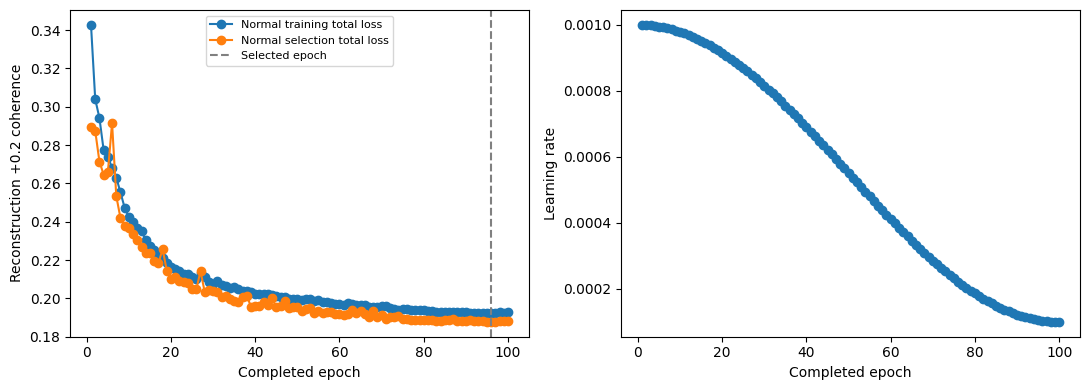

PosixPath('/kaggle/working/INPFormer_baseline_9_report.zip')

In [6]:
@torch.inference_mode()
def normal_validation():
    model.eval()
    sums = np.zeros(3,dtype=np.float64)
    count = 0
    for _,inp in clean_loader('select'):
        check_session_time()
        inp=inp.to(DEVICE,non_blocking=True)
        en,de,gather=model(inp)
        values=selection_values(en,de,gather)
        if not all(bool(torch.isfinite(v)) for v in values):
            raise FloatingPointError('Nonfinite normal-selection loss.')
        sums += np.asarray([v.item() for v in values])*len(inp)
        count += len(inp)
    return dict(zip(('select_total','select_reconstruction','select_coherence'),
                    (sums/count).tolist()))

def cpu_trainable_state():
    return {k:v.detach().cpu().clone() for k,v in trainable.state_dict().items()}

def optimizer_to_device(optimizer):
    for param,state in optimizer.state.items():
        for key in ('exp_avg','exp_avg_sq','max_exp_avg_sq'):
            if key in state:
                state[key]=state[key].to(param.device)

def scheduler_clock(scheduler):
    # Rebuild the source NumPy schedule from config; store only its safe clock.
    return dict(last_epoch=int(scheduler.last_epoch),_step_count=int(scheduler._step_count),
                _last_lr=[float(v) for v in scheduler.get_last_lr()])

def rng_state():
    return dict(torch_cpu=torch.get_rng_state(),
                torch_cuda=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else [])

def restore_rng(state):
    torch.set_rng_state(state['torch_cpu'])
    if DEVICE.type=='cuda':
        if len(state['torch_cuda'])!=torch.cuda.device_count():
            raise RuntimeError('Resume with the same visible GPU count.')
        torch.cuda.set_rng_state_all(state['torch_cuda'])

def meaningful_normal_improvement(value,anchor):
    if not math.isfinite(anchor):
        return True
    tolerance=max(EARLY_STOPPING_MIN_DELTA,
                  EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT*abs(anchor))
    return value<anchor-tolerance

def resume_bundle():
    destination=RUN.parent/'INPFormer_baseline_9_resume.zip'
    with zipfile.ZipFile(destination,'w',zipfile.ZIP_STORED) as z:
        for name in ('config.json','last.pt','best.pt','training_history.csv','status.json'):
            path=RUN/name
            if path.is_file():
                z.write(path,name)
    return destination

optimizer=StableAdamW([{'params':trainable.parameters()}],lr=LR,betas=(.9,.999),
                     weight_decay=1e-4,amsgrad=True,eps=1e-10)
scheduler=WarmCosineScheduler(optimizer,base_value=LR,final_value=1e-4,
                             total_iters=TOTAL_STEPS_CAP,warmup_iters=WARMUP_STEPS)
for group in optimizer.param_groups:
    group['lr']=float(group['lr'])

completed,validated_epochs,stale,best_epoch=0,0,0,0
best_value=stop_anchor=float('inf')
best_weights=None
history=[]
epoch_sums=[0.,0.,0.]
epoch_frames=0
epoch_seconds=0.
checkpoint_rng=None
if (RUN/'last.pt').exists():
    saved=load_pt(RUN/'last.pt')
    if saved['config_sha256']!=digest(config):
        raise RuntimeError('Checkpoint/config mismatch.')
    trainable.load_state_dict(saved['trainable'],strict=True)
    optimizer.load_state_dict(saved['optimizer'])
    optimizer_to_device(optimizer)
    scheduler.load_state_dict({**scheduler.state_dict(),**saved['scheduler_clock']})
    completed,validated_epochs=saved['step'],saved['validated_epochs']
    stale,best_epoch,best_value=saved['stale'],saved['best_epoch'],saved['best_value']
    stop_anchor=saved['stop_anchor']
    best_weights,history=saved['best_weights'],saved['history']
    epoch_sums,epoch_frames=saved['epoch_sums'],saved['epoch_frames']
    epoch_seconds,checkpoint_rng=saved['epoch_seconds'],saved['rng']
    del saved
    if not (validated_epochs*STEPS_PER_EPOCH<=completed<=(validated_epochs+1)*STEPS_PER_EPOCH):
        raise RuntimeError('Inconsistent epoch/optimizer position.')
    print(f'Resume after{completed} updates; {validated_epochs} validated epochs; bestepoch{best_epoch}.')

def commit_training_state():
    save_pt(dict(trainable=cpu_trainable_state(),optimizer=optimizer.state_dict(),
        scheduler_clock=scheduler_clock(scheduler),step=completed,
        validated_epochs=validated_epochs,stale=stale,best_epoch=best_epoch,
        best_value=best_value,stop_anchor=stop_anchor,best_weights=best_weights,history=history,
        epoch_sums=epoch_sums,epoch_frames=epoch_frames,epoch_seconds=epoch_seconds,
        rng=rng_state(),config_sha256=digest(config)),RUN/'last.pt')
    pd.DataFrame(history).to_csv(RUN/'training_history.csv',index=False)

def write_training_status(status):
    write_json(RUN/'status.json',dict(status=status,optimizer_steps=completed,
        completed_epochs=validated_epochs,max_epochs=EPOCHS,
        best_epoch=best_epoch,stale_epochs=stale,test_evaluated=False))

def train_remaining():
    global completed,validated_epochs,stale,best_epoch,best_value,best_weights,history
    global stop_anchor
    global epoch_sums,epoch_frames,epoch_seconds
    if checkpoint_rng is not None:
        restore_rng(checkpoint_rng)
    if not (RUN/'last.pt').exists():
        commit_training_state()  # Initialization checkpoint; epoch0 is not eligible.
    progress=tqdm(total=TOTAL_STEPS_CAP,initial=completed,desc='INP-Former optimizer updates')
    try:
        while validated_epochs<EPOCHS and stale<EARLY_STOPPING_PATIENCE:
            end_step=(validated_epochs+1)*STEPS_PER_EPOCH
            # A saved state can be at an epoch boundary with validation pending.
            if completed<end_step:
                sampler=EpochBatchSampler(len(train_dataset),BATCH,SEED,completed,end_step)
                loader=DataLoader(train_dataset,batch_sampler=sampler,num_workers=WORKERS,
                    pin_memory=DEVICE.type=='cuda',persistent_workers=False,
                    generator=torch.Generator().manual_seed(SEED+912+validated_epochs))
                model.train()
                model.encoder.eval()
                assert not any(p.requires_grad for p in model.encoder.parameters())
                tick=time.monotonic()
                for _,inp in loader:
                    check_session_time()
                    inp=inp.to(DEVICE,non_blocking=True)
                    optimizer.zero_grad(set_to_none=True)
                    en,de,gather=model(inp)
                    reconstruction=global_cosine_hm_adaptive(en,de,y=3)
                    loss=reconstruction+.2*gather
                    if not bool(torch.isfinite(loss)):
                        raise FloatingPointError('Nonfinite source training loss. No silent model/epsilon change.')
                    loss.backward()
                    grad_norm=nn.utils.clip_grad_norm_(trainable.parameters(),max_norm=.1,
                                                       error_if_nonfinite=True)
                    optimizer.step()
                    scheduler.step()
                    for group in optimizer.param_groups:
                        group['lr']=float(group['lr'])
                    completed+=1
                    n=len(inp)
                    epoch_sums=[a+v.item()*n for a,v in zip(epoch_sums,(loss,reconstruction,gather))]
                    epoch_frames+=n
                    progress.update(1)
                    del inp,en,de,gather,reconstruction,loss
                    now=time.monotonic()
                    epoch_seconds+=now-tick
                    if completed%SAVE_EVERY==0 or completed==end_step:
                        commit_training_state()
                        write_training_status('training')
                        elapsed=epoch_seconds/max(1,completed-validated_epochs*STEPS_PER_EPOCH)
                        progress.set_postfix(epoch=validated_epochs+1,
                            loss=epoch_sums[0]/epoch_frames,seconds_per_update=f'{elapsed:.2f}')
                    tick=time.monotonic()
                del loader
            if completed!=end_step or epoch_frames!=len(train_dataset):
                raise RuntimeError('An epoch must contain all normal training frames exactly once.')
            tick=time.monotonic()
            values=normal_validation()
            validation_seconds=time.monotonic()-tick
            selection=float(values['select_total'])
            improved=meaningful_normal_improvement(selection,stop_anchor)
            validated_epochs+=1
            # Best-model selection and stopping tolerance have different roles:
            # retain even small real improvements in the evaluated checkpoint.
            if selection<best_value:
                best_value,best_epoch=selection,validated_epochs
                best_weights=cpu_trainable_state()
            if improved:
                stop_anchor,stale=selection,0
            else:
                stale+=1
            history.append(dict(
                epoch=validated_epochs,optimizer_steps=completed,
                train_total=epoch_sums[0]/epoch_frames,
                train_reconstruction=epoch_sums[1]/epoch_frames,
                train_coherence=epoch_sums[2]/epoch_frames,**values,
                frames_this_epoch=epoch_frames,
                training_seconds=epoch_seconds,validation_seconds=validation_seconds,
                lr=float(optimizer.param_groups[0]['lr']),
                unclipped_grad_norm=float(grad_norm) if 'grad_norm' in locals() else None,
                best_epoch=best_epoch,stale_epochs=stale,stop_anchor=stop_anchor,
                meaningful_improvement=improved))
            print(f'\nEpoch{validated_epochs}/{EPOCHS}: train={history[-1]["train_total"]:.6f}, '
                  f'normal={selection:.6f}, bestepoch={best_epoch}, stale={stale}, '
                  f'seconds={epoch_seconds+validation_seconds:.1f}',flush=True)
            mean_epoch=sum(h['training_seconds']+h['validation_seconds'] for h in history)/len(history)
            print(f'Estimated remaining training/validation to cap: '
                  f'{mean_epoch*(EPOCHS-validated_epochs)/3600:.2f} hours; '
                  'normal-only early stopping can finish earlier.',flush=True)
            epoch_sums,epoch_frames,epoch_seconds=[0.,0.,0.],0,0.
            commit_training_state()
            write_training_status('training')
    except SessionPause as exc:
        # Called only between fully applied updates or in gradient-free validation.
        # Commit all applied steps. An unfinished normal validation is repeated.
        commit_training_state()
        write_training_status('paused_for_resume')
        print('\n',exc,'Scientific budget unchanged; test evaluation is skipped.',flush=True)
    except BaseException:
        # Do not serialize a possibly partly applied failed optimizer update.
        # last.pt is the last atomic committed state; at most99 updates are replayed.
        report_zip()
        if (RUN/'last.pt').exists():
            resume_bundle()
        raise
    finally:
        progress.close()

train_remaining()
TRAINING_COMPLETE=validated_epochs>=EPOCHS or stale>=EARLY_STOPPING_PATIENCE
history_df=pd.DataFrame(history)
if TRAINING_COMPLETE:
    if best_weights is None or best_epoch<1:
        raise RuntimeError('No normal-selected trained checkpoint.')
    # Self-contained best.pt contains the frozen backbone and trained heads.
    # last.pt contains the final optimizer state and the best-head snapshot.
    trainable.load_state_dict(best_weights,strict=True)
    best_path=RUN/'best.pt'
    if not best_path.exists():
        save_pt(dict(model={k:v.detach().cpu() for k,v in model.state_dict().items()},
            epoch=best_epoch,normal_select_loss=best_value,config_sha256=digest(config),
            backbone_sha256=BACKBONE_SHA256),best_path)
    selected=load_pt(best_path)
    if selected['epoch']!=best_epoch or selected['config_sha256']!=digest(config):
        raise RuntimeError('Saved best checkpoint mismatch.')
    model.load_state_dict(selected['model'],strict=True)
    del selected
    model.eval()
    write_json(RUN/'selected_checkpoint.json',dict(
        epoch=best_epoch,completed_epochs=validated_epochs,optimizer_steps=completed,
        checkpoint='best.pt',sha256=sha(best_path),normal_selection_loss=best_value,
        selection='lowest observed normal-only total loss; stopping tolerance is separate; no test selection',
        stopping_anchor=stop_anchor,
        stop_reason='normal_patience' if stale>=EARLY_STOPPING_PATIENCE else 'maximum_epoch_cap'))
else:
    print('Training paused. Later cells skip calibration/test. Save output and set RESUME_DIR next session.')
    display(FileLink(str(resume_bundle())))
if len(history_df):
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    axes[0].plot(history_df.epoch,history_df.train_total,'o-',label='Normal training total loss')
    axes[0].plot(history_df.epoch,history_df.select_total,'o-',label='Normal selection total loss')
    axes[0].axvline(best_epoch,color='gray',linestyle='--',label='Selected epoch')
    axes[0].set(xlabel='Completed epoch',ylabel='Reconstruction +0.2 coherence')
    axes[0].legend(fontsize=8)
    axes[1].plot(history_df.epoch,history_df.lr,'o-')
    axes[1].set(xlabel='Completed epoch',ylabel='Learning rate')
    fig.tight_layout()
    fig.savefig(RUN/'training_curve.png',dpi=150)
    plt.show()
report_zip()


## 7. Thresholds locked before test masks

Preserve the historical Q3+4IQR rule and common morphology. Also fit five fixed calibration quantiles using calibration only and measure achieved FPR on the independent audit split. The historical rule includes audit images and is explicitly labelled accordingly. Interrupted scoring resumes from saved map cursors.


In [7]:
STRUCT=generate_binary_structure(2,2)

def postprocess(mask):
    m=binary_closing(mask,structure=STRUCT,iterations=2)
    m=binary_opening(m,structure=STRUCT,iterations=1)
    m=binary_fill_holes(m)
    cc,_=label(m)
    keep=np.bincount(cc.ravel())>=50
    keep[0]=False
    return binary_opening(keep[cc],structure=STRUCT,iterations=2)

@torch.inference_mode()
def score_maps(role):
    model.eval()
    score=SCORES[0]
    path=MAP_DIR/f'{score}_{role}.npy'
    partial_path=path.with_name(path.stem+'.work.npy')
    cursor=path.with_name(path.stem+'.progress.json')
    shape=(len(splits[role]),SIZE,SIZE)
    identity=dict(config_sha256=digest(config),checkpoint_sha256=sha(RUN/'best.pt'),
                  role=role,shape=list(shape))
    # Cache identity includes the selected checkpoint, not just the model name.
    if PREVIOUS and not path.exists() and not partial_path.exists():
        old_dir=PREVIOUS/'_cache'/MAP_DIR.name
        old_cursor=old_dir/cursor.name
        if old_cursor.exists():
            old_state=json.loads(old_cursor.read_text())
            if all(old_state.get(k)==v for k,v in identity.items()):
                old_path=old_dir/(path.name if old_state.get('complete') else partial_path.name)
                if old_path.exists():
                    target=path if old_state.get('complete') else partial_path
                    shutil.copy2(old_path,target)
                    shutil.copy2(old_cursor,cursor)
    if path.exists():
        if not cursor.exists():
            raise RuntimeError('Completed score cache lacks provenance.')
        info=json.loads(cursor.read_text())
        if any(info.get(k)!=v for k,v in identity.items()):
            raise RuntimeError('Score cache identity mismatch.')
        if not info.get('complete'):
            # Recover a process exit between the final array rename and cursor commit.
            # The final-batch cursor was committed only AFTER all rows were flushed.
            if int(info.get('next_frame',-1))!=shape[0]:
                raise RuntimeError('Completed score cache has an incomplete cursor.')
            write_json(cursor,dict(info,complete=True))
    else:
        if partial_path.exists() and cursor.exists():
            info=json.loads(cursor.read_text())
            if any(info.get(k)!=v for k,v in identity.items()):
                raise RuntimeError('Partial score cache identity mismatch.')
            start=int(info['next_frame'])
            elapsed=float(info.get('seconds',0.))
            data=np.load(partial_path,mmap_mode='r+')
        else:
            # A partially created array without an atomic cursor has no committed rows.
            data=np.lib.format.open_memmap(partial_path,mode='w+',dtype=np.float32,shape=shape)
            start,elapsed=0,0.
        if data.shape!=shape or data.dtype!=np.float32 or not 0<=start<=shape[0]:
            raise RuntimeError('Invalid partial score cache.')
        tick=time.monotonic()
        next_frame=start
        try:
            for indices,inp in tqdm(clean_loader(role,start=start),desc='Score '+role):
                check_session_time()
                inp=inp.to(DEVICE,non_blocking=True)
                en,de,gather=model(inp)
                result=source_score(en,de).cpu().numpy()
                if not np.isfinite(result).all():
                    raise FloatingPointError('Nonfinite native feature score.')
                ids=indices.numpy()
                if not np.array_equal(ids,np.arange(next_frame,next_frame+len(ids))):
                    raise RuntimeError('Scoring order mismatch.')
                data[ids]=result
                next_frame+=len(ids)
                if next_frame%100<EVAL_BATCH or next_frame==shape[0]:
                    data.flush()
                    write_json(cursor,dict(**identity,next_frame=next_frame,complete=False,
                        seconds=elapsed+time.monotonic()-tick))
                del inp,en,de,gather,result
        except SessionPause:
            data.flush()
            write_json(cursor,dict(**identity,next_frame=next_frame,complete=False,
                seconds=elapsed+time.monotonic()-tick))
            del data
            raise
        data.flush()
        del data
        partial_path.replace(path)
        elapsed+=time.monotonic()-tick
        write_json(cursor,dict(**identity,next_frame=shape[0],complete=True,seconds=elapsed))
        write_json(RUN/f'scoring_runtime_{role}.json',dict(frames=shape[0],seconds=elapsed,
            evaluation_batch=EVAL_BATCH,
            description='score generation/loading/transforms; excludes setup/copy; not isolated GPU latency'))
    result=np.load(path,mmap_mode='r')
    if result.shape!=shape or result.dtype!=np.float32:
        raise RuntimeError('Invalid completed score map.')
    if not all(np.isfinite(frame).all() for frame in result):
        raise FloatingPointError('Nonfinite cached score map.')
    runtime_path=RUN/f'scoring_runtime_{role}.json'
    if not runtime_path.exists():
        info=json.loads(cursor.read_text())
        write_json(runtime_path,dict(frames=shape[0],seconds=float(info.get('seconds',0.)),
            evaluation_batch=EVAL_BATCH,
            description='recorded score generation time recovered from completed cache cursor'))
    return {score:result}

def calibrate_scores():
    maps={role:score_maps(role) for role in ('select','calibrate','audit')}
    thresholds,audit_rows={},[]
    for score in SCORES:
        check_session_time()
        vals=np.concatenate([maps[r][score].ravel() for r in ('select','calibrate','audit')])
        q1,q3=np.percentile(vals,[25,75])
        thresholds[score]={'historical':float(q3+4*(q3-q1))}
        del vals
        rng=np.random.default_rng(SEED+71)
        sample=np.concatenate([a.ravel()[rng.choice(SIZE*SIZE,4096,replace=False)]
                               for a in maps['calibrate'][score]])
        for fpr in FPRS:
            thresholds[score][f'fpr_{fpr:g}']=float(np.quantile(sample,1-fpr,method='higher'))
        for protocol,threshold in thresholds[score].items():
            raw,post=[],[]
            for a in maps['audit'][score]:
                pred=a>threshold
                raw.append(float(pred.mean()))
                post.append(float(postprocess(pred).mean()))
            audit_rows.append(dict(score=score,protocol=protocol,threshold=threshold,
                audit_raw_fpr=float(np.mean(raw)),audit_post_fpr=float(np.mean(post)),
                audit_used_in_threshold=(protocol=='historical')))
    write_json(RUN/'thresholds_LOCKED.json',thresholds)
    audit=pd.DataFrame(audit_rows)
    audit.to_csv(RUN/'normal_fpr.csv',index=False)
    write_json(RUN/'evaluation_lock.json',dict(
        checkpoint_sha256=sha(RUN/'best.pt'),config_sha256=digest(config),
        thresholds_sha256=sha(RUN/'thresholds_LOCKED.json'),test_masks_decoded=False))
    return maps,thresholds,audit

EVALUATION_READY=False
if TRAINING_COMPLETE:
    MAP_DIR=CACHE/('scores_'+sha(RUN/'best.pt')[:16])
    MAP_DIR.mkdir(exist_ok=True)
    try:
        maps,thresholds,audit=calibrate_scores()
        EVALUATION_READY=True
        print('Normal-selected checkpoint and thresholds locked; no test mask pixels used yet.')
        display(audit)
    except SessionPause as exc:
        write_json(RUN/'status.json',dict(status='paused_during_calibration',
            completed_epochs=validated_epochs,selected_epoch=best_epoch,
            optimizer_steps=completed,test_evaluated=False,reason=str(exc)))
        print(exc,'Retain the output folder including _cache; set RESUME_DIR next session.')
        report_zip()


Score select:   0%|          | 0/131 [00:00<?, ?it/s]

Resize calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Score calibrate:   0%|          | 0/32 [00:00<?, ?it/s]

Resize audit:   0%|          | 0/234 [00:00<?, ?it/s]

Score audit:   0%|          | 0/59 [00:20<?, ?it/s]

Normal-selected checkpoint and thresholds locked; no test mask pixels used yet.


,score,protocol,threshold,audit_raw_fpr,audit_post_fpr,audit_used_in_threshold
0,inpformer_feature_cosine,historical,0.304648,0.000000,0.000000,True
1,inpformer_feature_cosine,fpr_0.005,0.212054,0.008119,0.006864,False
2,inpformer_feature_cosine,fpr_0.01,0.202803,0.015283,0.013408,False
3,inpformer_feature_cosine,fpr_0.02,0.192205,0.030016,0.027410,False
4,inpformer_feature_cosine,fpr_0.05,0.174926,0.075105,0.072357,False
5,inpformer_feature_cosine,fpr_0.1,0.157899,0.146070,0.145846,False


## 8. Mean IoU and the other metrics

Report mean per-frame anomaly IoU prominently, with Dice, precision/recall, pooled metrics, pixel AP/AUROC/AUPRO and image metrics when defined. Evaluate all496 test frames after the checkpoint and thresholds are locked. Keep every fixed operating point; no test-selected threshold or model.


In [8]:
def confusion(pred, target):
    return (int(np.count_nonzero(pred & target)), int(np.count_nonzero(pred & ~target)),
            int(np.count_nonzero(~pred & target)), int(np.count_nonzero(~pred & ~target)))

def iou(tp, fp, fn):
    return tp / (tp + fp + fn) if tp + fp + fn else 1.0

def dice(tp, fp, fn):
    return 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0

def pixel_ranking(scores, masks):
    # Exact AP/AUROC, with tied scores grouped, using a single sorting pass.
    # PRO gives every 8-connected GT region equal weight, integrates FPR<=0.30,
    # and normalizes by 0.30. Test labels here calculate metrics, not thresholds.
    y = np.asarray(masks, dtype=np.bool_).ravel()
    score = np.asarray(scores, dtype=np.float32).ravel()
    positives, negatives = int(y.sum()), int((~y).sum())
    if positives == 0 or negatives == 0:
        return dict(pixel_ap=None, pixel_auroc=None, pixel_aupro_0p30=None,
                    gt_regions=0, positive_pixels=positives, negative_pixels=negatives)
    weights = np.zeros(masks.shape, dtype=np.float32)
    regions = 0
    for i, m in enumerate(masks):
        cc, n = label(m, structure=STRUCT)
        areas = np.bincount(cc.ravel())
        lookup = np.zeros(len(areas), dtype=np.float32)
        lookup[1:] = 1. / areas[1:]
        weights[i] = lookup[cc]
        regions += n
    order = np.argsort(score, kind='stable')[::-1]
    sorted_scores = score[order]
    ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(score) - 1]
    del sorted_scores
    cumsum = np.cumsum(y[order], dtype=np.int64)
    tp = cumsum[ends].astype(np.float64)
    del cumsum
    fp = (ends + 1).astype(np.float64) - tp
    ap = float(np.sum(np.diff(np.r_[0., tp]) * (tp / (ends + 1))) / positives)
    fpr = np.r_[0., fp / negatives]
    tpr = np.r_[0., tp / positives]
    trapz = getattr(np, 'trapezoid', None) or np.trapz
    auroc = float(trapz(tpr, fpr))
    del tp, fp, tpr
    region_cumsum = np.cumsum(weights.ravel()[order], dtype=np.float64)
    pro = np.r_[0., region_cumsum[ends] / regions]
    del region_cumsum, weights, order, ends
    cap = .30
    # Keep all vertical segments at a repeated FPR; interpolate the crossing segment.
    right = int(np.searchsorted(fpr, cap, side='right'))
    xx, yy = fpr[:right], pro[:right]
    if xx[-1] < cap:
        upper = right
        endpoint = yy[-1] + (pro[upper] - yy[-1]) * (cap - xx[-1]) / (fpr[upper] - xx[-1])
        xx = np.r_[xx, cap]
        yy = np.r_[yy, endpoint]
    aupro = float(trapz(yy, xx) / cap)
    return dict(pixel_ap=ap, pixel_auroc=auroc, pixel_aupro_0p30=aupro,
                gt_regions=int(regions), positive_pixels=positives, negative_pixels=negatives)

def evaluate_test():
    # Check the lock before accessing any test label content.
    lock = json.loads((RUN / 'evaluation_lock.json').read_text())
    assert lock['config_sha256'] == digest(config)
    assert lock['checkpoint_sha256'] == sha(RUN / 'best.pt')
    assert lock['thresholds_sha256'] == sha(RUN / 'thresholds_LOCKED.json')
    maps['test'] = score_maps('test')
    gt = np.lib.format.open_memmap(CACHE / 'test_masks.npy', mode='w+', dtype=np.bool_,
                                 shape=(len(splits['test']), SIZE, SIZE))
    mask_hashes = []
    for i, r in enumerate(tqdm(splits['test'], desc='Decode test masks after lock')):
        with Image.open(r['mask']) as im:
            gt[i] = np.asarray(im.convert('L').resize((SIZE, SIZE), Image.Resampling.BILINEAR),
                               dtype=np.float32) / 255 > .5
        mask_hashes.append(dict(relative=r['relative'], sha256=sha(r['mask'])))
    gt.flush()
    assert gt.any() and not gt.all()
    write_json(RUN / 'mask_hashes.json', mask_hashes)
    rows = []
    for s in SCORES:
        for protocol, t in tqdm(thresholds[s].items(), desc='Masks ' + s):
            for i, r in enumerate(splits['test']):
                raw = maps['test'][s][i] > t
                for processing, pred in [('raw', raw), ('postprocessed', postprocess(raw))]:
                    tp, fp, fn, tn = confusion(pred, gt[i])
                    rows.append(dict(score=s, protocol=protocol, processing=processing,
                                     relative=r['relative'], video=r['video'], tp=tp, fp=fp, fn=fn, tn=tn,
                                     iou=iou(tp, fp, fn), dice=dice(tp, fp, fn),
                                     precision=tp / (tp + fp) if tp + fp else 0.,
                                     recall=tp / (tp + fn) if tp + fn else 0.))
    frames = pd.DataFrame(rows)
    frames.to_csv(RUN / 'test_frame_metrics.csv', index=False)
    keys = ['score', 'protocol', 'processing']
    summaries = []
    for (s, protocol, processing), group in frames.groupby(keys, sort=False):
        tp, fp, fn, tn = [int(group[c].sum()) for c in ('tp', 'fp', 'fn', 'tn')]
        a = audit[(audit.score == s) & (audit.protocol == protocol)].iloc[0]
        summaries.append(dict(
            model=MODEL_LABEL, score=s, protocol=protocol, processing=processing,
            mean_frame_iou=float(group.iou.mean()), mean_iou=float(group.iou.mean()),
            median_frame_iou=float(group.iou.median()), mean_frame_dice=float(group.dice.mean()),
            mean_frame_precision=float(group.precision.mean()), mean_frame_recall=float(group.recall.mean()),
            pooled_iou=iou(tp, fp, fn), pooled_dice=dice(tp, fp, fn),
            pooled_precision=tp / (tp + fp) if tp + fp else 0.,
            pooled_recall=tp / (tp + fn) if tp + fn else 0.,
            audit_raw_fpr=float(a.audit_raw_fpr), audit_post_fpr=float(a.audit_post_fpr),
            audit_used_in_threshold=bool(a.audit_used_in_threshold), threshold=float(a.threshold),
            n_frames=len(group), total_parameters=PARAMETERS, selected_epoch=best_epoch, completed_epochs=validated_epochs, optimizer_steps=completed,
            trainable_parameters=TRAINABLE_PARAMETERS, frozen_parameters=FROZEN_PARAMETERS,
        ))
    summary = pd.DataFrame(summaries)
    summary.to_csv(RUN / 'summary.csv', index=False)
    frames.groupby(keys + ['video'], as_index=False).agg(
        mean_frame_iou=('iou', 'mean'), mean_frame_dice=('dice', 'mean'),
        frames=('iou', 'size')).to_csv(RUN / 'test_video_metrics.csv', index=False)
    ranking = []
    for s in SCORES:
        print('Exact full-pixel AP / AUROC / AUPRO:', s, flush=True)
        ranking.append(dict(score=s, **pixel_ranking(maps['test'][s], gt)))
    ranking = pd.DataFrame(ranking)
    ranking.to_csv(RUN / 'full_pixel_ranking.csv', index=False)
    headline = summary[(summary.processing == 'postprocessed') &
                       summary.protocol.isin(['historical', 'fpr_0.02'])].merge(ranking, on='score')
    headline.to_csv(RUN / 'headline_metrics.csv', index=False)
    print('Historical row: inpformer_feature_cosine / historical / postprocessed / mean_frame_iou')
    display(headline[['score', 'protocol', 'mean_frame_iou', 'mean_frame_dice',
                      'pooled_precision', 'pooled_recall', 'pixel_ap', 'pixel_auroc', 'audit_post_fpr']])
    # Native source image score: mean of the largest1% of pixel scores.
    # Do not mix independent audit frames into the test set just to manufacture negatives.
    from sklearn.metrics import average_precision_score, roc_auc_score
    image_rows, image_ranking = [], []
    for s in SCORES:
        image_scores = []
        for a in maps['test'][s]:
            flat = np.asarray(a).ravel()
            k = max(1, int(len(flat) * .01))
            image_scores.append(float(np.partition(flat, len(flat)-k)[-k:].mean()))
        image_labels = np.asarray([bool(m.any()) for m in gt], dtype=np.int64)
        for i, r in enumerate(splits['test']):
            image_rows.append(dict(score=s, relative=r['relative'], video=r['video'],
                image_score=image_scores[i], mask_has_anomaly=int(image_labels[i])))
        valid = len(np.unique(image_labels)) == 2
        image_ranking.append(dict(score=s, normal_frames=int((image_labels==0).sum()),
            anomalous_frames=int((image_labels==1).sum()),
            image_ap=float(average_precision_score(image_labels, image_scores)) if valid else None,
            image_auroc=float(roc_auc_score(image_labels, image_scores)) if valid else None,
            note='top1% source image score; labels from evaluated masks' if valid else
                 'Undefined discrimination: test split does not contain both image classes.'))
    pd.DataFrame(image_rows).to_csv(RUN / 'test_image_scores.csv', index=False)
    write_json(RUN / 'image_ranking.json', image_ranking)
    return gt, frames, summary, ranking, headline


EVALUATION_COMPLETE = False
if EVALUATION_READY:
    try:
        gt,frames,summary,ranking,headline = evaluate_test()
        EVALUATION_COMPLETE = True
    except SessionPause as exc:
        write_json(RUN / 'status.json', dict(status='paused_during_evaluation',
            completed_epochs=validated_epochs, selected_epoch=best_epoch,
            optimizer_steps=completed, test_evaluated=False, reason=str(exc)))
        print(exc, 'Keep best.pt, last.pt, config.json and _cache. Resume with the same settings.')
        report_zip()


Resize test:   0%|          | 0/496 [00:00<?, ?it/s]

Score test:   0%|          | 0/124 [00:00<?, ?it/s]

Decode test masks after lock:   0%|          | 0/496 [00:00<?, ?it/s]

Masks inpformer_feature_cosine:   0%|          | 0/6 [00:00<?, ?it/s]

Exact full-pixel AP / AUROC / AUPRO: inpformer_feature_cosine
Historical row: inpformer_feature_cosine / historical / postprocessed / mean_frame_iou


,score,protocol,mean_frame_iou,mean_frame_dice,pooled_precision,pooled_recall,pixel_ap,pixel_auroc,audit_post_fpr
0,inpformer_feature_cosine,historical,0.000189,0.000374,0.985047,0.000223,0.481185,0.852079,0.00000
1,inpformer_feature_cosine,fpr_0.02,0.326943,0.482546,0.454127,0.586239,0.481185,0.852079,0.02741


## 9. Figures and compact report

Plot the training curve and IoU against achieved normal FPR. Show three fixed examples with input, ground truth, feature error and masks. Write all small CSV/JSON/source/figure files to the report ZIP; keep large checkpoints and caches for resume.


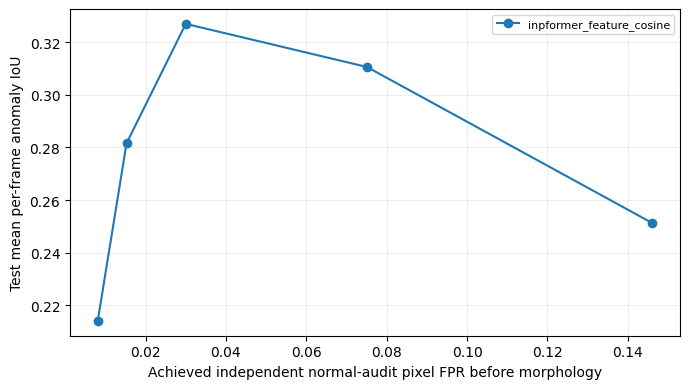

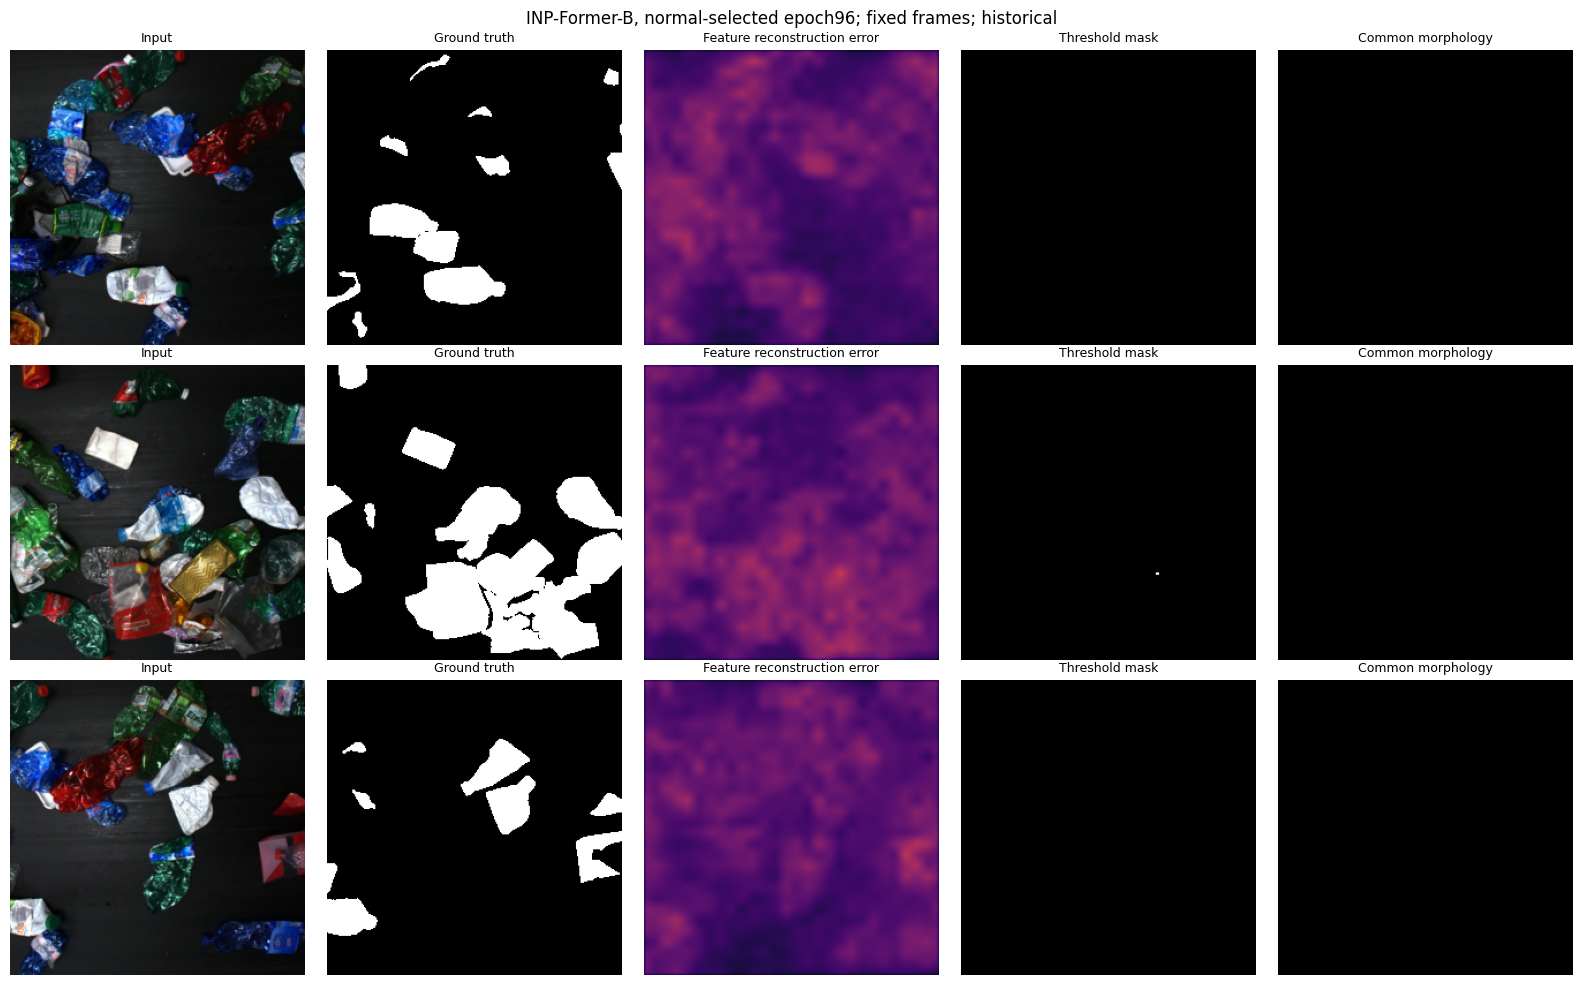

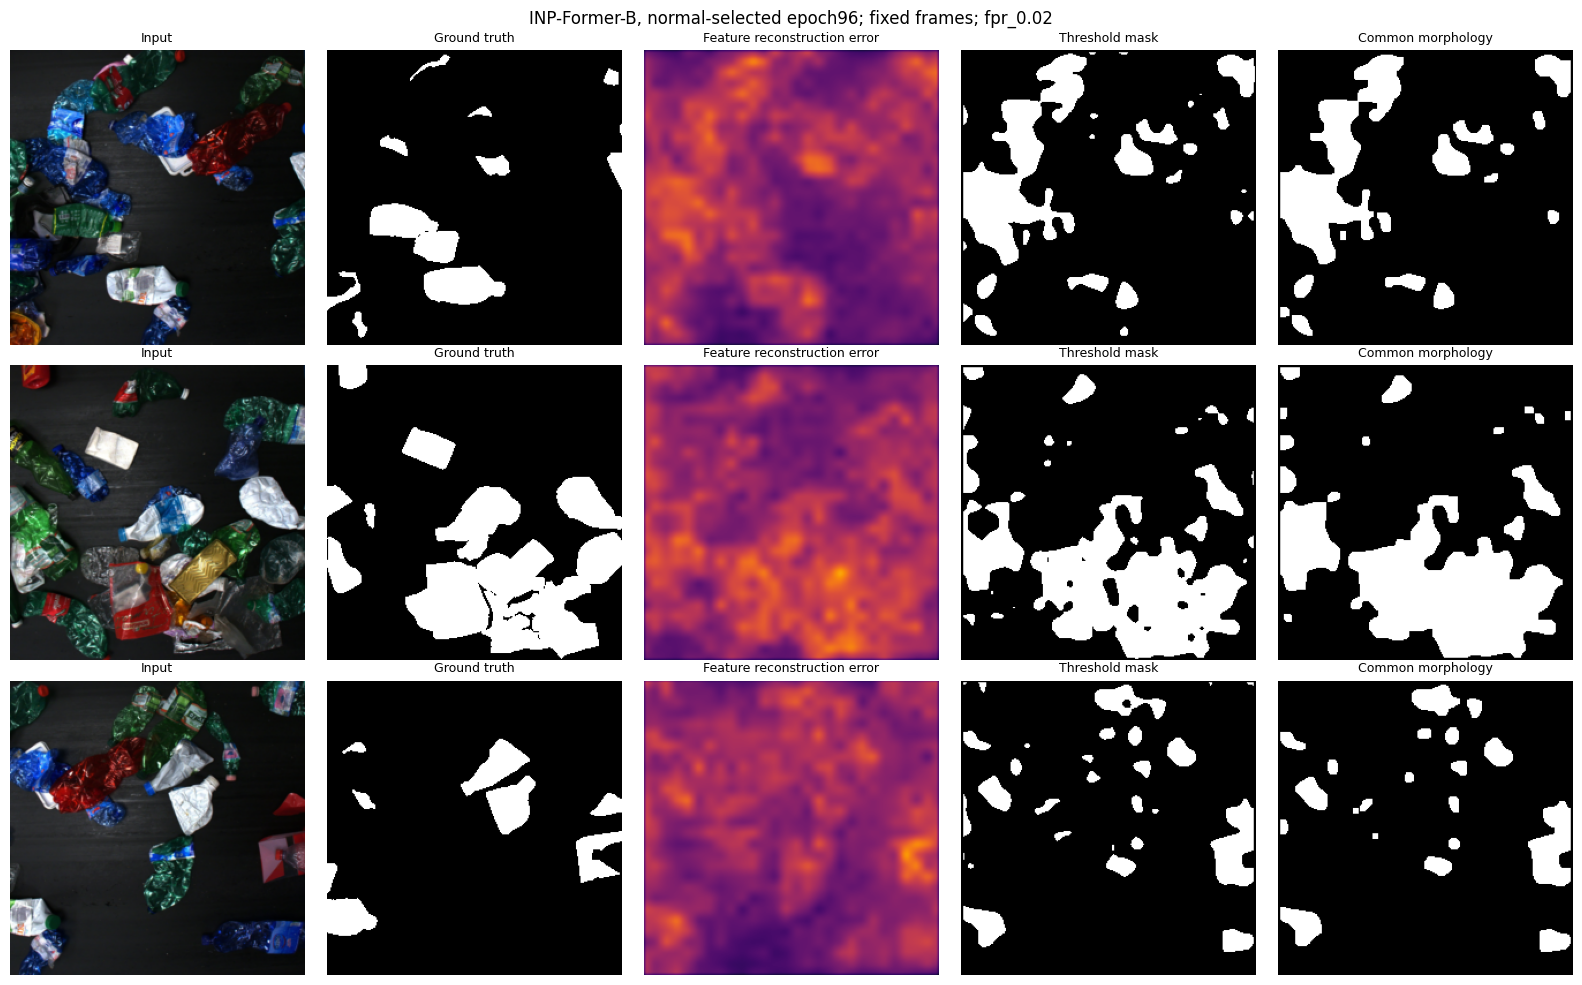

Original INP-Former (CVPR2025), WS2 comparison baseline9

Source: https://github.com/luow23/INP-Former/tree/17d265381d9b323a2ef6e05aab0665a85edebe84
Paper: Exploring Intrinsic Normal Prototypes within a Single Image for Universal Anomaly Detection.
Run: max100 epochs, batch4, normal-only patience10,
Stopping: >0.1% improvement from the last meaningful
normal-loss anchor, with an absolute numerical floor1e-08.
Completed100 epochs/95800 updates.
Primary checkpoint: best.pt, normal-selected epoch96; normal loss=0.18774698757621927.
Checkpoint selection retains the lowest observed normal loss, even if an improvement
is too small to reset early-stopping patience. These are separate rules.
One epoch exposes all3829 normal fullframes once; the last short batch is included.
Epoch0 is saved for recovery but not eligible for the evaluated checkpoint.

This is a declared COMMON100-EPOCH-CAP adaptation, not the authors200-epoch recipe.
The earlier QMEM T1 extension ran10 additional epochs and sele

,model,score,protocol,processing,mean_frame_iou,mean_iou,median_frame_iou,mean_frame_dice,mean_frame_precision,mean_frame_recall,...,completed_epochs,optimizer_steps,trainable_parameters,frozen_parameters,pixel_ap,pixel_auroc,pixel_aupro_0p30,gt_regions,positive_pixels,negative_pixels
0,INPFormer_B_reg4_WS2_fullframe_392_max100_norm...,inpformer_feature_cosine,historical,postprocessed,0.000189,0.000189,0.000000,0.000374,0.024003,0.000189,...,100,95800,68517984,86583552,0.481185,0.852079,0.49009,3688,4732744,27773112
1,INPFormer_B_reg4_WS2_fullframe_392_max100_norm...,inpformer_feature_cosine,fpr_0.02,postprocessed,0.326943,0.326943,0.324337,0.482546,0.440186,0.562827,...,100,95800,68517984,86583552,0.481185,0.852079,0.49009,3688,4732744,27773112


/kaggle/working/INPFormer_baseline_9_report.zip

Retain the entire Kaggle output folder, especially last.pt, best.pt, config.json and _cache.


In [9]:
def final_report():
    fig,ax=plt.subplots(figsize=(7,4))
    for score in SCORES:
        data=summary[(summary.score==score)&(summary.processing=='postprocessed')&
                     (summary.protocol!='historical')].sort_values('audit_raw_fpr')
        ax.plot(data.audit_raw_fpr,data.mean_frame_iou,'o-',label=score)
    ax.set(xlabel='Achieved independent normal-audit pixel FPR before morphology',
           ylabel='Test mean per-frame anomaly IoU')
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(RUN/'iou_vs_fpr.png',dpi=150)
    plt.show()
    indices=np.linspace(0,len(splits['test'])-1,3,dtype=int)
    data=cache_images('test')
    score=SCORES[0]
    for protocol in ('historical','fpr_0.02'):
        fig,axes=plt.subplots(3,5,figsize=(16,10))
        threshold=thresholds[score][protocol]
        for row,idx in enumerate(indices):
            panels=[(data[idx],'Input',None),(gt[idx],'Ground truth','gray'),
                (maps['test'][score][idx],'Feature reconstruction error','inferno'),
                (maps['test'][score][idx]>threshold,'Threshold mask','gray'),
                (postprocess(maps['test'][score][idx]>threshold),'Common morphology','gray')]
            for col,(arr,title,cmap) in enumerate(panels):
                axes[row,col].imshow(arr,cmap=cmap,vmin=0 if col==2 else None,
                                    vmax=max(2*threshold,1e-8) if col==2 else None)
                axes[row,col].set_title(title,fontsize=9)
                axes[row,col].axis('off')
        fig.suptitle(f'INP-Former-B, normal-selected epoch{best_epoch}; fixed frames; {protocol}')
        fig.tight_layout()
        fig.savefig(RUN/f'fixed_examples_{protocol}.png',dpi=150)
        plt.show()
    write_json(RUN/'fixed_examples.json',[splits['test'][int(i)]['relative'] for i in indices])
    write_json(RUN/'status.json',dict(
        status='complete',model=MODEL_LABEL,completed_epochs=validated_epochs,
        max_epochs=EPOCHS,optimizer_steps=completed,optimizer_step_cap=TOTAL_STEPS_CAP,
        training_image_presentations=validated_epochs*len(splits['train']),
        selected_epoch=best_epoch,selected_checkpoint='best.pt',
        normal_selection_loss=best_value,test_evaluated=True,
        stop_reason='normal_patience' if stale>=EARLY_STOPPING_PATIENCE else 'maximum_epoch_cap',
        total_parameters=PARAMETERS,trainable_parameters=TRAINABLE_PARAMETERS,
        frozen_parameters=FROZEN_PARAMETERS,
        training_validation_seconds=float(history_df.training_seconds.sum()+history_df.validation_seconds.sum()),
        peak_gpu_allocated_bytes=torch.cuda.max_memory_allocated() if DEVICE.type=='cuda' else None))
    text=f'''Original INP-Former (CVPR2025), WS2 comparison baseline9

Source: https://github.com/luow23/INP-Former/tree/{INPFORMER_COMMIT}
Paper: Exploring Intrinsic Normal Prototypes within a Single Image for Universal Anomaly Detection.
Run: max{EPOCHS} epochs, batch{BATCH}, normal-only patience{EARLY_STOPPING_PATIENCE},
Stopping: >{100*EARLY_STOPPING_MIN_RELATIVE_IMPROVEMENT:g}% improvement from the last meaningful
normal-loss anchor, with an absolute numerical floor{EARLY_STOPPING_MIN_DELTA}.
Completed{validated_epochs} epochs/{completed} updates.
Primary checkpoint: best.pt, normal-selected epoch{best_epoch}; normal loss={best_value}.
Checkpoint selection retains the lowest observed normal loss, even if an improvement
is too small to reset early-stopping patience. These are separate rules.
One epoch exposes all{len(splits['train'])} normal fullframes once; the last short batch is included.
Epoch0 is saved for recovery but not eligible for the evaluated checkpoint.

This is a declared COMMON100-EPOCH-CAP adaptation, not the authors200-epoch recipe.
The earlier QMEM T1 extension ran10 additional epochs and selected epoch10.
That result is historical, NOT matched to this new100-epoch protocol.
All methods, including the proposed QMEM+repair method, require the same new cap and
normal-only stopping/checkpoint policy for the matched-budget comparison.
This still does not match inherited Christian/external DINOv2 pretraining cost,
temporal input counts, exact update count, model capacity or FLOPs.
Older AE/VQVAE/MemAE/FAIR/RIAD/Dinomaly results with different training budgets remain
different-budget results until harmonized; this new notebook does not retroactively match them.
Matching a cap does not guarantee matching convergence, compute or model capacity.

Native map: source mean feature cosine discrepancy. This is FEATURE reconstruction,
not RGB reconstruction. There is no RGB decoder, RGB subtraction or anomaly-supervised head.
Six learned seed tokens aggregate image-specific prototypes; a bottleneck and eight source
prototype-guided blocks reconstruct fused encoder targets. Original source soft mining
reweights backward gradients by(relative local discrepancy)^3. The coherence/gather term,
weighted0.2, encourages normal training tokens to be close to their image-specific prototypes.
For normal validation, the same scalar loss is computed without backward-only hooks.
That is necessary because the official hook function requires tensors with gradients.

Frozen external encoder: official Meta self-supervised DINOv2-B with4 register tokens.
Updated on normal WS2: bottleneck, prototype seeds, extractor and guided decoder.
Parameters total={PARAMETERS}; trainable={TRAINABLE_PARAMETERS}; frozen={FROZEN_PARAMETERS}.
Counts include all12 instantiated encoder blocks; source forward uses blocks0..9.
Do not label this capacity-matched, external-data-free or a plain RGB AE competitor.

Retained: source model classes, six prototypes, source base architecture, layer fusion,
soft-mining train loss+0.2*gather, StableAdamW betas(.9,.999)/wd1e-4/eps1e-10,
warmup100 then cosine LR1e-3->1e-4 over the declared cap, clipnorm0.1,
native cosine score interpolation392->256 and Gaussian5x5/sigma4 with zero padding.
Changed:200epochs->shared100max, batch16->4, drop_lastTrue->False, seed1->1337,
448resize/392center-crop->same fullframe256 content enlarged to392, normal-only early
stopping and checkpoint selection, native Torch attention fallback, decoder activation
checkpointing, resumability and common WS2 metrics. All adaptations are fixed before test evaluation.
No per-image min/max normalization or extra model/map sweep is performed.

Historical comparison row: headline_metrics.csv, protocol=historical,
processing=postprocessed, mean_frame_iou. mean_iou is the identical alias.
Historical threshold: Q3+4*IQR over select+calibrate+audit native scores;
the audit is therefore not independent for this historical row.
Independent rows: fixed calibration targets{list(FPRS)}; achieved FPR measured on
audit only. Compare the same declared row/rule and morphology across methods.
The scalar thresholds differ by score type; feature methods use their native score.
Do not describe a historical feature-score IoU as RGB reconstruction IoU.

Mean IoU is per-frame FOREGROUND/anomaly IoU averaged over496 frames.
It is not pooled IoU and not a two-class foreground/background mIoU.
Empty union IoU/Dice=1; precision/recall empty denominator=0.
Also saved: mean Dice/precision/recall, pooled metrics, frame/video CSVs,
full-pixel AP/AUROC/AUPRO0..0.30, independent raw/post normal FPR and fixed examples.
Continuous metrics are computed before binary morphology. Pixel ranking retains all
pixels and groups ties; AUPRO gives equal weights to8-connected GT regions.
Image AP/AUROC use native top1% image scores and are reported only if both image
classes occur in the existing test split; no extra negatives are manufactured.

Only normal train images receive optimizer updates. Normal selection chooses checkpoint;
calibration chooses fixed thresholds; test masks are decoded only after the lock.
This existing test set has already been inspected in the project; do not call it a
newly blind holdout. Single-seed results do not establish statistical superiority.

Send INPFormer_baseline_9_report.zip and the executed notebook/log.
No large npy files or weights are needed initially.
Retain best.pt, last.pt, config.json and the _cache folder for resume/reproduction.
Resume ZIP contains checkpoints/config, not large caches. Full output-folder resume
also reuses image caches and partial score cursors.
'''
    (RUN/'REPORT.txt').write_text(text)
    print(text)

if EVALUATION_COMPLETE:
    final_report()
    display(headline)
else:
    print('Run not complete. Partial report contains status/provenance, not final benchmark results.')
display(FileLink(str(report_zip())))
print('Retain the entire Kaggle output folder, especially last.pt, best.pt, config.json and _cache.')


## Preparation checks

Verified before delivery:

- Notebook schema and Python 3.10 syntax; every required source file hash and the
  exact earlier WS2 manifest;100-epoch cap / batch4 / patience10 /
  relative stopping tolerance0.1% with absolute floor1e-8 settings.
- Real official DINOv2-B register weights loaded strictly; the full source INP-Former
  ran a 392×392 forward pass and a backward/official optimizer update on CPU.
  The final one-image batch has finite gradients; every trainable head/prototype
  receives gradients, while the frozen encoder remains unchanged.
- Native loss scalar and anomaly-map operations match the source. Decoder activation
  checkpointing preserves source block values and gradients in the CPU parity check.
- Actual notebook training, calibration, evaluation, figures and report paths executed
  on a small synthetic verification fixture using the original model classes.
  That fixture is not a waste-detection performance experiment.
- Interruption midway through an epoch and during pending epoch validation resumes
  to identical CPU weights, optimizer state and scheduler state. The100-epoch cap
  and patience10 stopping rule were exercised. Partial score-map recovery was tested.
- Shared morphology matches the earlier baseline; pixel AP/AUROC agree with
  scikit-learn, including tied scores; foreground mean IoU and its alias are present.
  Thresholds are locked before test masks are decoded.

Instantiated model counts: **155,101,536 total / 68,517,984 trainable /
86,583,552 frozen parameters**. Counts include all12 encoder blocks; the original
forward uses blocks0..9.

The full WS2 dataset run and GPU memory/runtime have **not** been executed here.
The notebook records those measurements when you run it on Kaggle. No WS2 accuracy
or promised training duration is inferred from the preparation checks.
